# Prédiction de la mortalité après un infarctus du myocarde

**Projet de Machine Learning** : Machine Learning/SDD/3AFISE/ISAE-supaero, année [2026-2027]

| | |
|---|---|
| **Auteurs** | Luce Georgiou, Neel Alibert, Maxim Gasnier |
| 

---

## 0 - Introduction

### 0.1 - Contexte

Après un infarctus du myocarde, l'état d'un patient peut évoluer vers de nombreuses complications (troubles du rythme, œdème pulmonaire, choc cardiogénique, rupture myocardique, etc.). Savoir tôt quels patients sont à haut risque de décès permet aux cliniciens d'orienter la surveillance et les ressources vers ceux qui en ont le plus besoin.

Nous travaillons sur le jeu de données public **Myocardial infarction complications**, issu de l'hôpital universitaire de Krasnoyarsk (Russie) et utilisé dans l'article suivant :

> Golovenkin S.E., Bac J., Chervov A., Mirkes E.M., Orlova Y.V., Barillot E., Gorban A.N., Zinovyev A. (2020). *Trajectories, bifurcations and pseudotime in large clinical datasets: applications to myocardial infarction and diabetes data.* arXiv:2007.03788.

Il contient **1700 patients**, **111 variables d'entrée** (*features*) et **12 complications** possibles. Les variables d'entrée sont de types variés (binaires, ordinales, continues) et comportent de nombreuses **valeurs manquantes**.

### 0.2 - Problématique

> **Peut-on prédire le décès d'un patient après un infarctus, d'abord dès son admission, puis après 3 jours de soins ? Les informations recueillies pendant ces 3 jours améliorent-elles la prédiction ?**

Il s'agit d'un problème d'**apprentissage supervisé**. On choisit de se restreindre à (*supervised learning*) de la **classification binaire** : la cible `y` vaut 0 si le patient survit et 1 s'il décède, quelle qu'en soit la cause.

### 0.3 - Hypothèses

- **H1** : certaines variables (âge, pression artérielle, marqueurs biologiques) se comportent différemment chez les patients décédés et chez les survivants, et suffisent à prédire le risque.
- **H2** : les variables du jour 3 apportent un gain de performance par rapport aux seules variables d'admission.
- **H3** : la classe « décès » étant minoritaire (environ 1 décès pour 5 survivants), il faut corriger ce déséquilibre pour que le modèle détecte les décès.

### 0.4 - Deux scénarios pour éviter la fuite de données

On construit deux jeux de variables :

| Objet | Contenu |
|---|---|
| `y` | la cible : décès (1) ou survie (0) |
| `X_admission` | variables connues **à l'admission** |
| `X_jour3` | toutes les variables d'entrée, connues **au 3ᵉ jour** |

Nous prenons soin de séparer les données à l'admission et après 3 jours pour éviter le **date leackage**. Toutes les transformation que nous allons éffectuer le seront uniquement à partir de la base de données d'entrainement, puis seront appliqué au jeu de test.

### 0.5 - Choix de la métrique

Nous choisissons de nous concentrer sur la métrique **recall** pour notre problème dans le but d'éviter les faux négatifs. Cela correspond à rater un decès ce qui est préjudisciable dans le cas de notre étude.

### 0.6 - Plan du notebook

1. **Chargement des données** : import, construction de `y`, `X_admission` et `X_jour3`
2. **Exploration** : types de variables, valeurs manquantes, déséquilibre, corrélations
3. **Séparation train / test** et étude des variables discriminantes
4. **Exploration non supervisée** : PCA et clustering
5. **Preprocessing** : colonnes vides, imputation, standardisation, déséquilibre des classes
6. **Feature engineering**
7. **Apprentissage et tuning** : validation croisée, XGBoost et SVM, discussion des hyperparamètres
8. **Évaluation** : seuil de décision, ROC, matrices de confusion
9. **Scénario Jour 3** et importance des variables
10. **Analyse des faux négatifs**
11. **Conclusion et perspectives**


## I - Chargement des données

### I.1 - Import des bibliotèques


In [1]:
# --- Bibliothèques standard ---
import os
import warnings

# --- Calcul et données ---
import numpy as np
import pandas as pd

# --- Visualisation ---
import matplotlib.pyplot as plt

# --- Scikit-learn : séparation, validation croisée, tuning ---
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    cross_val_predict,
    RandomizedSearchCV,
    validation_curve,
)

# --- Scikit-learn : preprocessing ---
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

# --- Scikit-learn : non supervisé (section 6) ---
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# --- Modèles ---
from sklearn.dummy import DummyClassifier   # baseline (section 7)
from sklearn.svm import SVC
from xgboost import XGBClassifier

# --- Métriques ---
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
)

# --- Statistiques (tests univariés, section 3) ---
from scipy.stats import mannwhitneyu

# --- Paramètres globaux, définis UNE SEULE FOIS pour tout le notebook ---
SEED = 42                      # reproductibilité : mêmes patients en train/test pour tout le groupe
N_SPLITS = 5                   # nombre de plis de la validation croisée
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

# Affichage
pd.set_option("display.max_columns", 120)
plt.rcParams["figure.dpi"] = 100
warnings.filterwarnings("ignore", category=FutureWarning)

### I.2 - Chargement du fichier CSV

Le fichier doit se trouver à côté du notebook ou dans un dossier `data/`. Si le programme ne trouve pas le fichier il affichera un message d'erreur *FilesNotFoundError*

On utilise `index_col="ID"` : la colonne `ID` identifie le patient, ce n'est pas une variable à donner au modèle.

In [2]:
NAME_FILES = "Myocardial_infarction_complications_Database.csv"
PATH_FILES = [NAME_FILES, os.path.join("data", NAME_FILES), os.path.join("..", "data", NAME_FILES)]

chemin = next((c for c in PATH_FILES if os.path.exists(c)), None)
if chemin is None:
    raise FileNotFoundError(
        f"{NAME_FILES} introuvable. Cherché dans : {PATH_FILES}. "
        "Copiez le CSV dans le dossier du notebook ou dans data/."
    )

df = pd.read_csv(chemin, index_col="ID")
print("Fichier chargé :", chemin)
print("Dimensions :", df.shape)   # attendu : (1700, 123) = 111 entrées + 12 complications

Fichier chargé : data/Myocardial_infarction_complications_Database.csv
Dimensions : (1700, 123)


## II - Explorations des données

### II.1 - Séparation entrée / complication

Les 12 dernières colonnes sont des **complications**. Toutes les autres sont des variables d'entrée.

In [3]:
COMPLICATIONS = [
    "FIBR_PREDS",  # fibrillation auriculaire
    "PREDS_TAH",   # tachycardie supraventriculaire
    "JELUD_TAH",   # tachycardie ventriculaire
    "FIBR_JELUD",  # fibrillation ventriculaire
    "A_V_BLOK",    # bloc auriculo-ventriculaire du 3e degré
    "OTEK_LANC",   # œdème pulmonaire
    "RAZRIV",      # rupture myocardique
    "DRESSLER",    # syndrome de Dressler
    "ZSN",         # insuffisance cardiaque chronique
    "REC_IM",      # récidive d'infarctus
    "P_IM_STEN",   # angine post-infarctus
    "LET_IS",      # issue létale : 0 = survie, 1 à 7 = cause du décès
]

# Variables d'entrée
X_all = df.drop(columns=COMPLICATIONS)

print(f"Variables d'entrée : {X_all.shape[1]}  |  Complications : {len(COMPLICATIONS)}  |  Patients : {X_all.shape[0]}")

Variables d'entrée : 111  |  Complications : 12  |  Patients : 1700


### II.2 Création de la cible

`LET_IS` vaut 0 si le patient survit, et de 1 à 7 selon la cause du décès (1 choc cardiogénique, 2 œdème pulmonaire, 3 rupture myocardique, 4 aggravation de l'insuffisance cardiaque, 5 thromboembolie, 6 asystolie, 7 fibrillation ventriculaire).

On choisit de **binariser** : 0 = survie, 1 = décès dans le but d'obtenir un problème de classification binaire.

Répartition de la cible
deces
survie    1429
décès      271
Name: count, dtype: int64
Proportion de décès : 15.9%


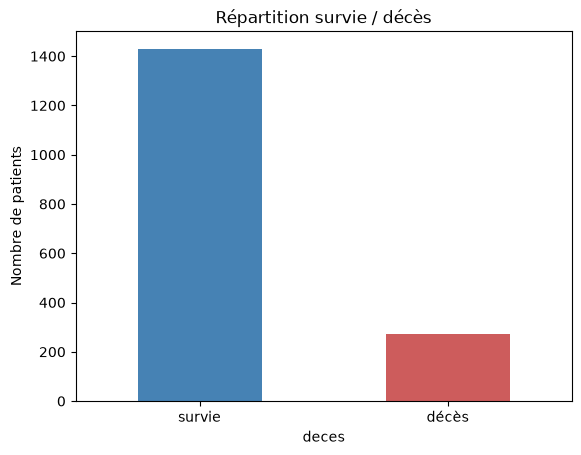

In [4]:
y = (df["LET_IS"] > 0).astype(int).rename("deces")

LABELS = {0: "survie", 1: "décès"}
repartition = y.value_counts().sort_index().rename(LABELS)

print("Répartition de la cible")
print(repartition)
print("Proportion de décès :", f"{y.mean():.1%}")

repartition.plot(kind="bar", color=["steelblue", "indianred"])
plt.title("Répartition survie / décès")
plt.ylabel("Nombre de patients")
plt.xticks(rotation=0)
plt.show()

On peut voir sur le graphique ci-dessus que la classe décès est minoritaire dans la base de données. Nous allons donc nous intéresser plutôt au **recall** car nous ne voulons pas rater de decès.

### II.3 Séparation variables admission et variables après 3 jour.

Pour pouvoir observer si la prévision de décès est meilleur sur les données récoltés 3 jours après l'admision nous séparons le dataset en 2. La première partie contient uniquement les données à l'admission et la deuxième contient en plus les données après 3 jours.

| Groupe | Colonnes | Moment où l'information existe |
|---|---|---|
| Antécédents, ECG, biologie, délai | `AGE` … `TIME_B_S` | à l'admission |
| Traitements des urgences | `NA_KB`, `NOT_NA_KB`, `LID_KB`, `NITR_S` | à l'admission (équipe d'urgence) |
| Douleur récurrente | `R_AB_1_n`, `R_AB_2_n`, `R_AB_3_n` | `_1_` premières heures, `_2_` jour 2, `_3_` jour 3 |
| Opioïdes en soins intensifs | `NA_R_1_n`, `NA_R_2_n`, `NA_R_3_n` | `_1_` premières heures, `_2_` jour 2, `_3_` jour 3 | |
| Anti-inflammatoires en soins intensifs | `NOT_NA_1_n`, `NOT_NA_2_n`, `NOT_NA_3_n` | `_1_` premières heures, `_2_` jour 2, `_3_` jour 3 | |
| Autres traitements en soins intensifs | `LID_S_n`, `B_BLOK_S_n`, `ANT_CA_S_n`, `GEPAR_S_n`, `ASP_S_n`, `TIKL_S_n`, `TRENT_S_n` | pendant le séjour (moment exact à vérifier) |

In [5]:
# Colonnes dont la valeur dépend de ce qui se passe APRÈS l'arrivée (jours 1 à 3)
COLONNES_APRES_ADMISSION = [
    "R_AB_1_n", "R_AB_2_n", "R_AB_3_n",          # récidive de la douleur
    "NA_R_1_n", "NA_R_2_n", "NA_R_3_n",          # opioïdes en soins intensifs
    "NOT_NA_1_n", "NOT_NA_2_n", "NOT_NA_3_n",    # anti-inflammatoires en soins intensifs
]

# Traitements en soins intensifs dont le moment exact est incertain.
# Si STRICT_ADMISSION = True, on les retire aussi du scénario « admission ».

COLONNES_SOINS_INTENSIFS_INCERTAINES = [
    "LID_S_n", "B_BLOK_S_n", "ANT_CA_S_n", "GEPAR_S_n", "ASP_S_n", "TIKL_S_n", "TRENT_S_n",
]

STRICT_ADMISSION = True

a_retirer = list(COLONNES_APRES_ADMISSION)
if STRICT_ADMISSION:
    a_retirer += COLONNES_SOINS_INTENSIFS_INCERTAINES

- `X_jour3` : toutes les variables d'entrée (information complète au 3ᵉ jour).
- `X_admission` : les mêmes, moins les colonnes de la cellule précédente.

In [6]:
X_jour3 = X_all.copy()
X_admission = X_all.drop(columns=a_retirer)

print("X_jour3     :", X_jour3.shape)
print("X_admission :", X_admission.shape)
print("Colonnes retirées pour l'admission :", len(a_retirer))

X_jour3     : (1700, 111)
X_admission : (1700, 95)
Colonnes retirées pour l'admission : 16


### II.4 - Définition des types de variables de `X_admission` et `X_jour3`

On cherche a donnée un type chacune des variables qui vont nous servir à entrainer le modèle. On distingue 3 types de variables :
- `binaire` pour les variables binaire
- `ordinal` (on place le seuil ordinale à 10)
- `continue`

On calcul également le pourcentage manquant pour chaque colonne

In [7]:
SEUIL_ORDINALE = 10  # au plus 10 modalités entières distinctes -> ordinale

def type_variable(s):
    """Classe une colonne en 'binaire', 'ordinale' ou 'continue' (NaN ignorés)."""
    valeurs = s.dropna().unique()
    if len(valeurs) <= 2:
        return "binaire"
    if np.all(valeurs == np.round(valeurs)) and len(valeurs) <= SEUIL_ORDINALE:
        return "ordinale"
    return "continue"

def resume_par_type(X):
    return pd.DataFrame({
        "type": X.apply(type_variable),
        "nb_modalites": X.nunique(),
        "min": X.min(),
        "max": X.max(),
        "moyenne": X.mean(),
        "% manquants": X.isna().mean() * 100,
    })

resume_all = resume_par_type(X_all)

print(resume_all["type"].value_counts())

affichage = False

if affichage:
    for t in ["binaire", "ordinale", "continue"]:
        print(f"\n=== Variables {t}s ===")
        display(resume_all[resume_all["type"] == t].drop(columns="type"))



type
binaire     78
ordinale    21
continue    12
Name: count, dtype: int64


### II.5 - Valeurs manquantes par patients

In [8]:
# Pourcentage de valeurs manquantes pour chaque patient (chaque ligne de X_all)

resume_patient = (
    X_all.isna().mean(axis=1)
    .mul(100)
    .round(2)
    .rename("% manquants")
    .to_frame()
)


# Résumé statistique du % de valeurs manquantes par patient
print("Pourcentage de valeurs manquantes par patient")
print(f"  Moyenne    : {resume_patient['% manquants'].mean():.1f} %")
print(f"  Médiane    : {resume_patient['% manquants'].median():.1f} %")
print(f"  Minimum    : {resume_patient['% manquants'].min():.1f} %")
print(f"  Maximum    : {resume_patient['% manquants'].max():.1f} %")


# Nombre de patients au-dessus de quelques seuils
for seuil in (10, 20, 30, 40):
    n = (resume_patient["% manquants"] > seuil).sum()
    print(f"Patients avec plus de {seuil} % de valeurs manquantes : {n} ({n / len(resume_patient):.1%})")

Pourcentage de valeurs manquantes par patient
  Moyenne    : 8.5 %
  Médiane    : 6.3 %
  Minimum    : 0.9 %
  Maximum    : 54.0 %
Patients avec plus de 10 % de valeurs manquantes : 373 (21.9%)
Patients avec plus de 20 % de valeurs manquantes : 140 (8.2%)
Patients avec plus de 30 % de valeurs manquantes : 62 (3.6%)
Patients avec plus de 40 % de valeurs manquantes : 4 (0.2%)


Pour la majorité des patients (taille de l'échantillon = 1700) nous avons moins de 10 % de valeurs manquantes.

## III - Séparation du jeu de données en train/test et matrice de corrélation

### III.1 - Sépration train/test

In [9]:
# 1. On sépare les PATIENTS (leurs identifiants), pas les tableaux.
#    Ainsi X_admission et X_jour3 ont exactement les mêmes patients de test.
idx_train, idx_test = train_test_split(
    y.index,
    test_size=0.2,    # 20 % des patients pour le test
    stratify=y,       # même proportion de décès dans le train et le test
    random_state=SEED,
)

# 2. On applique ce découpage aux deux scénarios et à la cible
X_adm_train, X_adm_test = X_admission.loc[idx_train], X_admission.loc[idx_test]
X_j3_train,  X_j3_test  = X_jour3.loc[idx_train],     X_jour3.loc[idx_test]
y_train, y_test = y.loc[idx_train], y.loc[idx_test]

# 3. Vérifications
print(f"Train : {len(idx_train)} patients, {y_train.sum()} décès ({y_train.mean():.1%})")
print(f"Test  : {len(idx_test)} patients, {y_test.sum()} décès ({y_test.mean():.1%})")

assert set(idx_train).isdisjoint(idx_test), "Des patients sont à la fois dans le train et le test"
assert X_adm_train.index.equals(X_j3_train.index) and X_adm_test.index.equals(X_j3_test.index)

Train : 1360 patients, 217 décès (16.0%)
Test  : 340 patients, 54 décès (15.9%)


### III.2 - Calcul de la matrice de corrélation

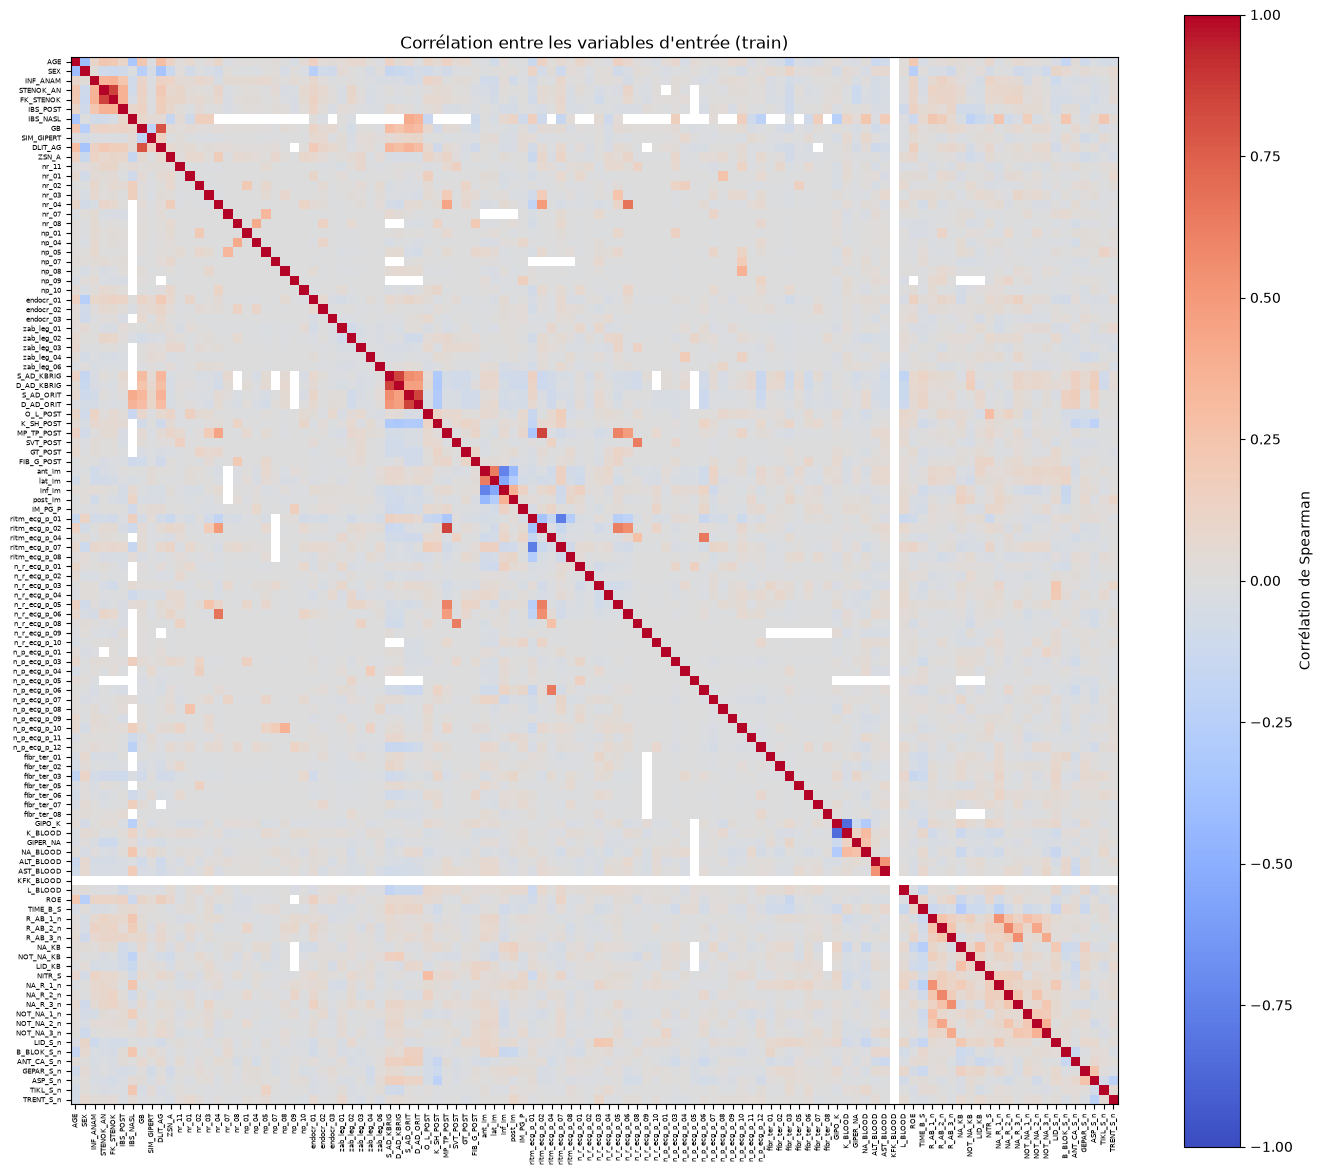

8 paires avec |corrélation| >= 0.7
STENOK_AN      FK_STENOK        0.86
S_AD_ORIT      D_AD_ORIT        0.85
GIPO_K         K_BLOOD         -0.85
S_AD_KBRIG     D_AD_KBRIG       0.84
MP_TP_POST     ritm_ecg_p_02    0.84
GB             DLIT_AG          0.79
ritm_ecg_p_01  ritm_ecg_p_07   -0.77
ant_im         inf_im          -0.74


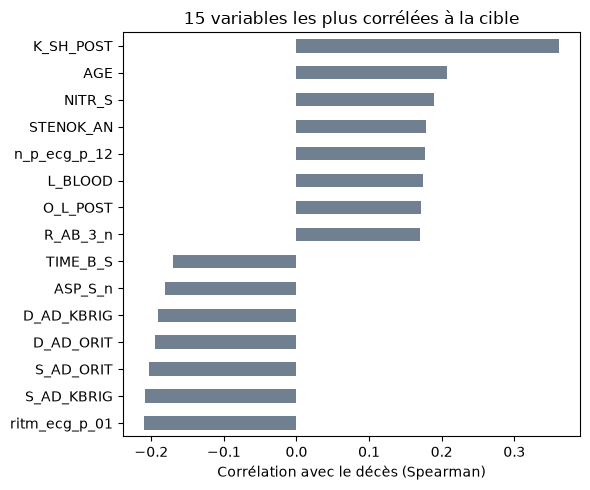

In [10]:
# 1. Données : toutes les features du jour 3, train uniquement.
#    On retire les colonnes constantes (une corrélation avec elles n'est pas définie).
donnees = X_j3_train.copy()
donnees = donnees.loc[:, donnees.nunique() > 1]

# 2. Matrice de corrélation de Spearman, calculée sur les patients où les deux variables sont connues.
#    min_periods : si moins de 30 patients ont les deux valeurs, la corrélation reste vide (NaN).
corr = donnees.corr(method="spearman", min_periods=30)

# 3. Heatmap
fig, ax = plt.subplots(figsize=(14, 12))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90, fontsize=5)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=5)
fig.colorbar(im, ax=ax, label="Corrélation de Spearman")
ax.set_title("Corrélation entre les variables d'entrée (train)")
plt.tight_layout()
plt.show()

# 4. Paires de variables fortement corrélées (on ne garde que le triangle supérieur pour éviter les doublons)
SEUIL = 0.7
haut = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
paires = haut[haut.abs() >= SEUIL].sort_values(key=abs, ascending=False)
print(f"{len(paires)} paires avec |corrélation| >= {SEUIL}")
print(paires.round(2).to_string())

# 5. Corrélation de chaque variable avec la cible (décès)
avec_cible = donnees.apply(lambda col: col.corr(y_train, method="spearman", min_periods=30))
top = avec_cible.reindex(avec_cible.abs().sort_values(ascending=False).index).head(15)

top.sort_values().plot(kind="barh", figsize=(6, 5), color="slategray")
plt.xlabel("Corrélation avec le décès (Spearman)")
plt.title("15 variables les plus corrélées à la cible")
plt.tight_layout()
plt.show()

## IV - Preprocessing des données

### IV.1 - Suppression des colonnes trop vides

**Objectif**

Retirer les variables qui contiennent trop de valeurs manquantes.

Ce traitement est appliqué séparément aux deux jeux de données (**ADM** et **J3**), chacun ayant sa propre liste de colonnes supprimées.

**Choix méthodologiques**

- **Seuil de 40 %** : valeur courante en pratique, qui représente un bon compromis entre conserver de l'information et éviter les colonnes trop pauvres. Ce seuil reste un paramètre ajustable (`SEUIL_NA`).
- **Absence de fuite de données (*data leakage*)** : les colonnes à supprimer sont déterminées à partir du jeu d'entraînement seul.
- **Cohérence des schémas** : une vérification (`assert`) contrôle que le jeu d'entraînement et le jeu de test ont exactement les mêmes colonnes, dans le même ordre, ce qui est nécessaire pour les étapes suivantes (imputation, standardisation, modélisation).

In [11]:
# --- Paramètres ---
SEUIL_NA = 0.4  # on supprime les colonnes avec plus de 40 % de valeurs manquantes
NA_DEGUISES = ["", "?", "unknown", "N/A"]

def supprimer_colonnes_vides(X_train, X_test, seuil=SEUIL_NA, nom=""):
    """Détermine les colonnes trop vides sur X_train, puis les retire de X_train et X_test."""
    # Harmonisation des NA déguisés
    X_train = X_train.replace(NA_DEGUISES, np.nan)
    X_test = X_test.replace(NA_DEGUISES, np.nan)

    # Taux de NA calculé sur le TRAIN uniquement
    taux_na = X_train.isna().mean().sort_values(ascending=False)
    cols_a_supprimer = taux_na[taux_na > seuil].index.tolist()

    # Récapitulatif
    print(f"===== {nom} =====")
    print("Taux de NA (train) pour les colonnes concernées :")
    print((taux_na[taux_na > 0] * 100).round(2).to_string(), "\n")
    print(f"Colonnes supprimées ({len(cols_a_supprimer)}) : {cols_a_supprimer}")

    # Application identique au train et au test
    X_train_clean = X_train.drop(columns=cols_a_supprimer)
    X_test_clean = X_test.drop(columns=cols_a_supprimer, errors="ignore")

    print(f"Train : {X_train.shape} -> {X_train_clean.shape}")
    print(f"Test  : {X_test.shape} -> {X_test_clean.shape}\n")

    # Sécurité : mêmes colonnes, dans le même ordre
    assert list(X_train_clean.columns) == list(X_test_clean.columns), \
        f"{nom} : les colonnes de train et de test ne correspondent pas"

    return X_train_clean, X_test_clean, cols_a_supprimer


# --- Application aux deux jeux de données ---
X_adm_train_clean, X_adm_test_clean, cols_supp_adm = supprimer_colonnes_vides(
    X_adm_train, X_adm_test, nom="ADM"
)

X_j3_train_clean, X_j3_test_clean, cols_supp_j3 = supprimer_colonnes_vides(
    X_j3_train, X_j3_test, nom="J3"
)

===== ADM =====
Taux de NA (train) pour les colonnes concernées :
KFK_BLOOD        99.71
IBS_NASL         95.29
S_AD_KBRIG       63.46
D_AD_KBRIG       63.46
NOT_NA_KB        40.22
LID_KB           39.63
NA_KB            38.24
NA_BLOOD         22.87
GIPER_NA         22.87
K_BLOOD          22.65
GIPO_K           22.50
AST_BLOOD        16.91
ALT_BLOOD        16.84
D_AD_ORIT        16.18
S_AD_ORIT        16.18
DLIT_AG          14.34
ROE              12.43
ritm_ecg_p_01     9.26
ritm_ecg_p_02     9.26
ritm_ecg_p_04     9.26
ritm_ecg_p_06     9.26
ritm_ecg_p_07     9.26
ritm_ecg_p_08     9.26
L_BLOOD           7.57
TIME_B_S          7.35
n_p_ecg_p_03      6.91
n_p_ecg_p_07      6.91
n_p_ecg_p_12      6.91
n_p_ecg_p_11      6.91
n_p_ecg_p_10      6.91
n_p_ecg_p_09      6.91
n_r_ecg_p_01      6.91
n_r_ecg_p_02      6.91
n_r_ecg_p_03      6.91
n_p_ecg_p_01      6.91
n_p_ecg_p_08      6.91
n_p_ecg_p_06      6.91
n_p_ecg_p_05      6.91
n_r_ecg_p_04      6.91
n_r_ecg_p_05      6.91
n_r_ecg_p_06  

### IV.2 - Imputation des valeurs manquante

Cette partie permet de remplacer les valeurs manquantes dans chacune des colonnes par une valeur que introduit le moins de biais possible. Tout en permettant au dataset d'être utlisé avec des modèles qui ne supporte pas les valeurs manquantes (ex SVM). Elle n'est donc pas forcément necessaire en fonction des méthodes qui vont être utilisé.
- On utilise la méthode de la médiane pour les variables continues
- On utlise la méthode des modes pour les variables binaire et ordinales

In [12]:
def imputer_mediane_mode(X_train, X_test, resume, nom=""):
    """Médiane pour les variables continues, mode pour les binaires et ordinales.
    L'imputeur est ajusté sur le train uniquement, puis appliqué au train et au test."""
    # On ne garde que les colonnes encore présentes après l'étape IV.1
    cols_cont = [c for c in X_train.columns if resume.loc[c, "type"] == "continue"]
    cols_mode = [c for c in X_train.columns if resume.loc[c, "type"] in ("binaire", "ordinale")]

    imputeur = ColumnTransformer(
        transformers=[
            ("mediane", SimpleImputer(strategy="median"), cols_cont),
            ("mode", SimpleImputer(strategy="most_frequent"), cols_mode),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")

    X_train_imp = imputeur.fit_transform(X_train)   # fit sur le train uniquement
    X_test_imp = imputeur.transform(X_test)         # simple application au test

    # Retour à l'ordre d'origine des colonnes
    X_train_imp = X_train_imp[X_train.columns]
    X_test_imp = X_test_imp[X_train.columns]

    print(f"===== {nom} =====")
    print(f"Continues (médiane) : {len(cols_cont)} | Binaires/ordinales (mode) : {len(cols_mode)}")
    print(f"NA restants - train : {X_train_imp.isna().sum().sum()} | test : {X_test_imp.isna().sum().sum()}\n")

    return X_train_imp, X_test_imp, imputeur


# --- Application aux deux jeux de données (après la suppression des colonnes vides) ---
X_adm_train_imp, X_adm_test_imp, imp_adm = imputer_mediane_mode(
    X_adm_train_clean, X_adm_test_clean, resume_all, nom="ADM"
)
X_j3_train_imp, X_j3_test_imp, imp_j3 = imputer_mediane_mode(
    X_j3_train_clean, X_j3_test_clean, resume_all, nom="J3"
)

===== ADM =====
Continues (médiane) : 9 | Binaires/ordinales (mode) : 81
NA restants - train : 0 | test : 0

===== J3 =====
Continues (médiane) : 9 | Binaires/ordinales (mode) : 97
NA restants - train : 0 | test : 0



### IV.3 - Feature engineering création de nouvelle variable

| Variable | Calcul | Intérêt médical |
|---|---|---|
| `PRESSION_PULSEE` | systolique − diastolique (soins intensifs) | une pression pulsée basse peut traduire un faible débit cardiaque (risque de choc cardiogénique) |
| `RATIO_AST_ALT` | AST / ALT | les deux enzymes augmentent pour des raisons différentes (cœur, foie) : leur rapport est plus informatif que chacune seule |
| `NB_TRAITEMENTS_URGENCES` | nombre de traitements reçus aux urgences (opioïdes, anti-inflammatoires, lidocaïne, nitrates) | résume l'intensité de la prise en charge initiale |

In [13]:
NOUVELLES_VARIABLES = ["PRESSION_PULSEE", "RATIO_AST_ALT", "NB_TRAITEMENTS_URGENCES"]
TRAITEMENTS_URGENCES = ["NA_KB", "NOT_NA_KB", "LID_KB", "NITR_S"]
COLONNES_REQUISES = ["S_AD_ORIT", "D_AD_ORIT", "ALT_BLOOD", "AST_BLOOD"] + TRAITEMENTS_URGENCES

def ajouter_features(X):
    """Ajoute 3 variables calculées ligne par ligne (aucun paramètre appris : pas de fuite de données).
    Les NaN se propagent : si une des composantes manque, la nouvelle variable manque aussi."""
    manquantes = [c for c in COLONNES_REQUISES if c not in X.columns]
    assert not manquantes, f"Colonnes nécessaires absentes : {manquantes}"

    X = X.copy()

    # 1. Pression pulsée = systolique - diastolique (soins intensifs)
    X["PRESSION_PULSEE"] = X["S_AD_ORIT"] - X["D_AD_ORIT"]

    # 2. Rapport AST/ALT (enzymes hépatiques). Division par 0 -> NaN, pas infini
    X["RATIO_AST_ALT"] = (X["AST_BLOOD"] / X["ALT_BLOOD"]).replace([np.inf, -np.inf], np.nan)

    # 3. Nombre de traitements reçus aux urgences (opioïdes, anti-inflammatoires, lidocaïne, nitrates)
    #    min_count=1 : NaN seulement si les 4 colonnes sont manquantes
    X["NB_TRAITEMENTS_URGENCES"] = X[TRAITEMENTS_URGENCES].sum(axis=1, min_count=1)

    return X

# Test sur un exemple (S=120, D=80 -> pression pulsée de 40)
exemple = pd.DataFrame({"S_AD_ORIT": [120.0], "D_AD_ORIT": [80.0], "ALT_BLOOD": [0.4], "AST_BLOOD": [0.2],
                        "NA_KB": [1.0], "NOT_NA_KB": [0.0], "LID_KB": [1.0], "NITR_S": [np.nan]})
print(ajouter_features(exemple)[NOUVELLES_VARIABLES].to_string(index=False))

 PRESSION_PULSEE  RATIO_AST_ALT  NB_TRAITEMENTS_URGENCES
            40.0            0.5                      2.0


On applique ces nouvelles colonnes dans les bases de données

In [14]:
types_avant = resume_all["type"].copy()

X_adm_train = ajouter_features(X_adm_train)
X_adm_test  = ajouter_features(X_adm_test)
X_j3_train  = ajouter_features(X_j3_train)
X_j3_test   = ajouter_features(X_j3_test)

# Les étapes de preprocessing (partie 5) lisent le type de chaque colonne dans `resume_all` :
# on le recalcule pour y inclure les nouvelles variables (le typage ne dépend pas de y).
resume_all = resume_par_type(pd.concat([X_j3_train, X_j3_test]))

# Vérifications
assert (resume_all.loc[types_avant.index, "type"] == types_avant).all(), "Un type existant a changé !"
assert list(X_adm_train.columns) == list(X_adm_test.columns)
assert list(X_j3_train.columns) == list(X_j3_test.columns)

print("X_adm_train :", X_adm_train.shape, "| X_j3_train :", X_j3_train.shape)
print("\nType des nouvelles variables :")
print(resume_all.loc[NOUVELLES_VARIABLES, ["type", "min", "max", "% manquants"]].round(2))

X_adm_train : (1360, 98) | X_j3_train : (1360, 114)

Type des nouvelles variables :
                             type    min     max  % manquants
PRESSION_PULSEE          continue -40.00  130.00        15.71
RATIO_AST_ALT            continue   0.04   14.33        16.82
NB_TRAITEMENTS_URGENCES  ordinale   0.00    4.00         0.12


,médiane survie,médiane décès,n survie,n décès,p-value
variable,,,,,
PRESSION_PULSEE,50.0,40.000,927,213,0.000
RATIO_AST_ALT,0.5,0.635,956,173,0.035
NB_TRAITEMENTS_URGENCES,1.0,1.000,1141,217,0.055


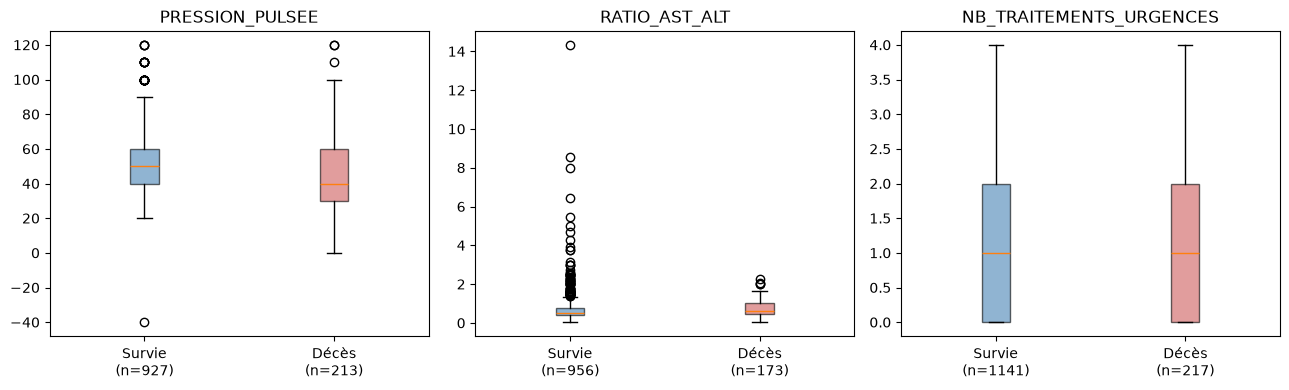

In [15]:
exploration_fe = X_j3_train[NOUVELLES_VARIABLES].copy()
exploration_fe["groupe"] = y_train.map({0: "Survie", 1: "Décès"})

lignes = []
for col in NOUVELLES_VARIABLES:
    surv = exploration_fe.loc[exploration_fe["groupe"] == "Survie", col].dropna()
    dec = exploration_fe.loc[exploration_fe["groupe"] == "Décès", col].dropna()
    _, p = mannwhitneyu(surv, dec)
    lignes.append({"variable": col, "médiane survie": surv.median(), "médiane décès": dec.median(),
                   "n survie": len(surv), "n décès": len(dec), "p-value": p})
display(pd.DataFrame(lignes).set_index("variable").round(3))

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col in zip(axes, NOUVELLES_VARIABLES):
    donnees = [exploration_fe.loc[exploration_fe["groupe"] == g, col].dropna() for g in ("Survie", "Décès")]
    bp = ax.boxplot(donnees, patch_artist=True)
    for patch, couleur in zip(bp["boxes"], ("steelblue", "indianred")):
        patch.set_facecolor(couleur); patch.set_alpha(0.6)
    ax.set_xticklabels([f"Survie\n(n={len(donnees[0])})", f"Décès\n(n={len(donnees[1])})"])
    ax.set_title(col)
plt.tight_layout()
plt.show()

### IV.3 - Standardisation des colonnes continues

**Objectif**

Mettre les variables continues à la même échelle (moyenne 0, écart-type 1). Sans cela, les variables aux grandes valeurs dominent les modèles sensibles à l'échelle (régression logistique, SVM, KNN, réseaux de neurones), et la régularisation (L1/L2, Elastic Net) pénalise les coefficients de façon inégale.

**Méthode**

- Utilisation de `StandardScaler` sur les variables de type **continue** uniquement (repérées grâce au tableau des types).
- Les variables **binaires** et **ordinales** restent inchangées, car les standardiser ferait perdre leur interprétation.
- Le scaler est **ajusté sur le jeu d'entraînement uniquement**, puis appliqué au jeu de test, afin d'éviter toute fuite de données.
- Traitement appliqué séparément aux jeux **ADM** et **J3**.

**Vérification**

Sur le train, les variables continues ont une moyenne proche de 0 et un écart-type de 1. Sur le test, les valeurs sont proches mais pas exactes, ce qui est normal.

**Étape suivante** : gestion du déséquilibre de classes (poids de classes ou SMOTE, appliqué uniquement dans le pipeline d'entraînement).

In [16]:
def standardiser_continues(X_train, X_test, resume, nom=""):
    """Standardise uniquement les variables continues (moyenne 0, écart-type 1).
    Le scaler est ajusté sur le train uniquement, puis appliqué au test."""
    cols_cont = [c for c in X_train.columns if resume.loc[c, "type"] == "continue"]

    scaler = ColumnTransformer(
        transformers=[("scale", StandardScaler(), cols_cont)],
        remainder="passthrough",              # binaires et ordinales inchangées
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")

    X_train_sc = scaler.fit_transform(X_train)   # fit sur le train uniquement
    X_test_sc = scaler.transform(X_test)

    # Retour à l'ordre d'origine des colonnes
    X_train_sc = X_train_sc[X_train.columns]
    X_test_sc = X_test_sc[X_train.columns]

    print(f"===== {nom} =====")
    print(f"Variables standardisées : {len(cols_cont)}")
    # Correction ici : on applique round() global de Python sur le max
    max_mean = round(X_train_sc[cols_cont].mean().abs().max(), 6)
    unique_std = X_train_sc[cols_cont].std(ddof=0).round(6).unique()[:3]
    print("Train - moyenne ~0 :", max_mean,
          "| écart-type ~1 :", unique_std, "\n")

    return X_train_sc, X_test_sc, scaler


X_adm_train_sc, X_adm_test_sc, scaler_adm = standardiser_continues(
    X_adm_train_imp, X_adm_test_imp, resume_all, nom="ADM"
)
X_j3_train_sc, X_j3_test_sc, scaler_j3 = standardiser_continues(
    X_j3_train_imp, X_j3_test_imp, resume_all, nom="J3"
)

===== ADM =====
Variables standardisées : 9
Train - moyenne ~0 : 0.0 | écart-type ~1 : [1.] 

===== J3 =====
Variables standardisées : 9
Train - moyenne ~0 : 0.0 | écart-type ~1 : [1.] 



### IV.4 - Desequilibre des classes

In [17]:
def poids_de_classes(y_train, nom=""):
    """Affiche la répartition des classes et les poids 'balanced' calculés sur le train."""
    classes = np.unique(y_train)
    poids = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)

    resume = pd.DataFrame({
        "effectif": pd.Series(y_train).value_counts().sort_index(),
        "proportion (%)": (pd.Series(y_train).value_counts(normalize=True).sort_index() * 100).round(2),
        "poids balanced": poids.round(3),
    })
    print(f"===== {nom} =====")
    print(resume, "\n")
    return dict(zip(classes, poids))

poids_adm = poids_de_classes(y_train)


=====  =====
       effectif  proportion (%)  poids balanced
deces                                          
0          1143           84.04           0.595
1           217           15.96           3.134 



## VI - Apprentissage et tuning

On vient réaliser le tuning des hyperparamètres grâce à la Cross-Validation.

La méthode de recherche choisie pour trouver la combinaison optimale est la Random Search, afin de faire un compromis entre performance et vitesse d'exécution.

Les modèles de prédictions choisis sont **XGBoost** (méthode de Gradient Boosting), et **SVM** (méthode de régression), afin de déterminer quel modèle permettra d'obtenir les meilleurs résultats.

Ces résultats sont évalués à l'aide du recall et du f1-score, un indicateur adapté dans ce contexte médical, puisque l'on accorde ici une forte importance aux décès manqués, plus qu'à une performance globale "meilleure".

### VI.1 - XGBoost avec réglages par défaut

In [28]:
# Ratio pour le déséquilibre de classes (1429 survies / 271 décès ≈ 5.3)
ratio_classes = (y_train == 0).sum() / (y_train == 1).sum()

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# Modèle de base
xgb_base = XGBClassifier(
    scale_pos_weight=ratio_classes,  # compense le déséquilibre
    eval_metric="logloss",
    random_state=SEED
)

# Évaluation en validation croisée sur le train
scores_f1 = cross_val_score(xgb_base, X_adm_train_imp, y_train, cv=cv, scoring="f1")

print(f"F1-scores (5-folds) : {scores_f1.round(3)}")
print(f"F1-score moyen : {scores_f1.mean():.3f} (± {scores_f1.std():.3f})")

F1-scores (5-folds) : [0.621 0.514 0.602 0.558 0.533]
F1-score moyen : 0.566 (± 0.040)



Avant de régler les hyperparamètres, on mesure les performances d'un XGBoost **non réglé**. Ce score sert de référence : le réglage de la partie suivante n'est utile que s'il fait mieux.

Ce que fait la cellule :

1. **Validation croisée** : `cv` découpe le train en 5 parties de taille égale (*plis*). Chaque pli sert à tour de rôle de validation pendant que le modèle s'entraîne sur les 4 autres. Le découpage est **stratifié** : chaque pli garde environ 16 % de décès. `shuffle=True` mélange les patients avant le découpage, et `random_state=SEED` rend le résultat reproductible.

2. **Modèle de base** : un `XGBClassifier` avec ses réglages par défaut, sauf deux paramètres :
   - `scale_pos_weight=ratio_classes` donne aux décès un poids environ 5,3 fois plus fort pendant l'apprentissage. Sans lui, le modèle serait tenté de prédire presque toujours « survie » ;
   - `eval_metric="logloss"` fixe la mesure d'erreur interne utilisée par XGBoost pendant l'entraînement. Elle n'influence pas le score affiché ci-dessous.

3. **Score** : `cross_val_score` entraîne le modèle 5 fois et renvoie un **F1-score** par pli. Le F1 de la classe « décès » est la moyenne harmonique entre la précision (parmi les patients annoncés à risque, combien sont vraiment décédés) et le recall (parmi les décès réels, combien sont détectés). Il est bas si l'un des deux est faible, ce qui le rend adapté à une classe rare.

**Lecture du résultat.** On regarde la moyenne des 5 scores et leur écart-type. Un écart-type élevé signifie que le score dépend beaucoup du pli choisi, ce qui est attendu avec seulement 217 décès dans le train. Cette moyenne est le score à battre lors du réglage des hyperparamètres.

### VI.2 - Réglage des hyperparamètres de XGBoost (Random Search)

XGBoost par défaut n'est pas forcément le meilleur réglage pour nos données. On cherche donc la combinaison d'**hyperparamètres** qui donne le meilleur F1-score en validation croisée sur le train.

**Espace de recherche.** `param_grid` liste, pour six hyperparamètres, les valeurs à essayer :

| Hyperparamètre | Valeurs testées | Rôle |
|---|---|---|
| `n_estimators` | 100, 200, 300 | nombre d'arbres construits |
| `max_depth` | 3, 4, 6, 8 | profondeur maximale de chaque arbre |
| `learning_rate` | 0,01 ; 0,05 ; 0,1 ; 0,2 | poids de chaque nouvel arbre (pas d'apprentissage) |
| `subsample` | 0,7 ; 0,8 ; 1,0 | part des patients utilisée par chaque arbre |
| `colsample_bytree` | 0,6 ; 0,8 ; 1,0 | part des variables utilisée par chaque arbre |
| `min_child_weight` | 1, 3, 5 | poids minimal exigé dans une feuille |

**Lecture du résultat.** On compare le meilleur F1 obtenu au F1 de XGBoost par défaut (cellule précédente). Un gain important montre que le réglage compte ; un gain faible signifie que le modèle est peu sensible à ces hyperparamètres, et que la difficulté vient plutôt des données (peu de décès, nombreuses valeurs manquantes).

In [19]:
# Grille d'hyperparamètres à explorer
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 4, 6, 8],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "min_child_weight": [1, 3, 5]
}

search_adm = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=param_grid,
    n_iter=20,              # nombre de combinaisons testées
    cv=cv,                  # StratifiedKFold
    scoring="f1",           # optimisation ciblée sur le F1-score
    random_state=SEED,
    n_jobs=-1
)

search_adm.fit(X_adm_train_imp, y_train)

print(f"Meilleur F1-score en CV : {search_adm.best_score_:.3f}")
print("Meilleurs hyperparamètres :", search_adm.best_params_)

Meilleur F1-score en CV : 0.597
Meilleurs hyperparamètres : {'subsample': 0.7, 'n_estimators': 300, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.1, 'colsample_bytree': 1.0}


### VI.3 - Choix du seuil de décision

XGBoost ne répond pas directement « décès » ou « survie » : il calcule une **probabilité de décès** pour chaque patient. La prédiction s'obtient en comparant cette probabilité à un **seuil**. Le seuil par défaut (0,5) n'est pas adapté à notre problème, car les décès sont rares et leur probabilité dépasse rarement 0,5. En contexte médical, rater un décès (faux négatif) est bien plus grave qu'une fausse alerte (faux positif). On abaisse donc le seuil pour détecter plus de décès, au prix de plus de fausses alertes.

**Objectif fixé : un recall d'au moins 80 %** (détecter au moins 8 décès sur 10).

**Méthode.**
1. `cross_val_predict` calcule, pour chaque patient du train, une probabilité de décès prédite par un modèle qui **ne l'a pas vu à l'entraînement** (prédiction « hors pli »). Ces probabilités sont donc réalistes, ce qui n'est pas le cas si l'on prédit sur les données d'entraînement.
2. `precision_recall_curve` calcule, pour chaque seuil possible, le recall et la précision correspondants. Quand le seuil augmente, le recall diminue.
3. Parmi les seuils qui garantissent un recall ≥ 80 %, on retient le **plus élevé** : c'est celui qui génère le moins de fausses alertes pour ce niveau de recall.

**Précaution contre la fuite de données.** Le seuil est choisi **uniquement sur le train**. Le jeu de test n'intervient pas dans ce choix, il servira seulement à vérifier le résultat (VI.5).

Seuil retenu pour un recall >= 80% : 0.160
Sur le train (validation croisée), la précision à ce seuil est de 43.5%


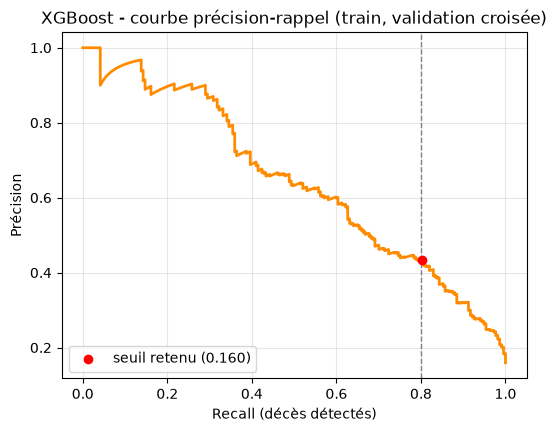

In [20]:
# Meilleur modèle trouvé par la recherche d'hyperparamètres
best_model_adm = search_adm.best_estimator_

# Probabilités de décès « hors pli » sur le train :
# chaque patient est prédit par un modèle qui ne l'a pas vu à l'entraînement
y_proba_train_cv = cross_val_predict(
    best_model_adm,
    X_adm_train_imp,
    y_train,
    cv=cv,
    method="predict_proba"
)[:, 1]

# Courbe précision-rappel sur le train
precisions, recalls, thresholds = precision_recall_curve(y_train, y_proba_train_cv)

# Seuil le plus élevé qui garantit un recall >= 80 %
RECALL_CIBLE = 0.80
idx_rappel_cible = np.where(recalls[:-1] >= RECALL_CIBLE)[0]
assert len(idx_rappel_cible) > 0, f"Aucun seuil n'atteint un recall de {RECALL_CIBLE:.0%}"

seuil_medical = thresholds[idx_rappel_cible[-1]]
precision_au_seuil = precisions[idx_rappel_cible[-1]]
print(f"Seuil retenu pour un recall >= {RECALL_CIBLE:.0%} : {seuil_medical:.3f}")
print(f"Sur le train (validation croisée), la précision à ce seuil est de {precision_au_seuil:.1%}")

# Courbe précision-rappel avec le point retenu
plt.figure(figsize=(6, 4.5))
plt.plot(recalls, precisions, color="darkorange", lw=2)
plt.scatter([recalls[idx_rappel_cible[-1]]], [precision_au_seuil], color="red", zorder=3,
            label=f"seuil retenu ({seuil_medical:.3f})")
plt.axvline(RECALL_CIBLE, color="gray", linestyle="--", lw=1)
plt.xlabel("Recall (décès détectés)")
plt.ylabel("Précision")
plt.title("XGBoost - courbe précision-rappel (train, validation croisée)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### VI.4 - Évaluation de XGBoost sur le jeu de test

C'est la **première et unique utilisation du jeu de test** pour ce modèle. On applique le seuil choisi en VI.4 aux probabilités prédites sur les patients de test, puis on lit la matrice de confusion :

|  | Prédit survie | Prédit décès |
|---|---|---|
| **Réellement survie** | vrais négatifs | **fausses alertes** (faux positifs) |
| **Réellement décès** | **décès manqués** (faux négatifs) | décès détectés (vrais positifs) |

Les deux cases en gras sont les erreurs. Les décès manqués sont les plus graves : c'est ce que le seuil cherche à limiter. Le rapport de classification donne ensuite, pour la classe « Décès » :
- le **recall** : part des décès réels détectés ;
- la **précision** : part des alertes qui concernent un vrai décès, c'est le prix à payer en fausses alertes ;
- le **F1-score** : compromis entre les deux.

**Lecture du résultat.** Le recall obtenu sur le test devrait être proche de 80 %, mais pas identique : le seuil a été fixé sur le train, et le test ne contient que 54 décès (un décès de plus ou de moins change le recall d'environ 2 points). La précision indique combien de patients sont surveillés inutilement pour atteindre ce niveau de détection.

===== XGBoost - Test, seuil à 0.160 =====
Matrice de confusion [[VN, FP], [FN, VP]] :
[[229  57]
 [ 11  43]]
              precision    recall  f1-score   support

      Survie       0.95      0.80      0.87       286
       Décès       0.43      0.80      0.56        54

    accuracy                           0.80       340
   macro avg       0.69      0.80      0.71       340
weighted avg       0.87      0.80      0.82       340



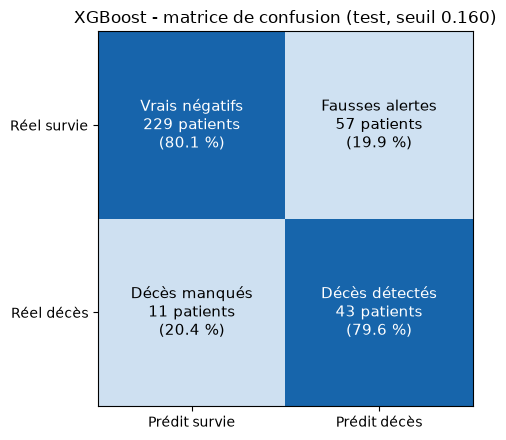

In [21]:
# Application du seuil choisi sur le train aux patients de test
y_proba_test = best_model_adm.predict_proba(X_adm_test_imp)[:, 1]
y_pred_medical = (y_proba_test >= seuil_medical).astype(int)

print(f"===== XGBoost - Test, seuil à {seuil_medical:.3f} =====")
print("Matrice de confusion [[VN, FP], [FN, VP]] :")
print(confusion_matrix(y_test, y_pred_medical))
print(classification_report(y_test, y_pred_medical, target_names=["Survie", "Décès"]))

# Matrice de confusion : effectifs et pourcentage de chaque vraie classe
cm = confusion_matrix(y_test, y_pred_medical)
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100   # chaque ligne = 100 % de la vraie classe
noms = [["Vrais négatifs", "Fausses alertes"], ["Décès manqués", "Décès détectés"]]

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=100)
for i in range(2):
    for j in range(2):
        couleur = "white" if cm_pct[i, j] > 50 else "black"
        ax.text(j, i, f"{noms[i][j]}\n{cm[i, j]} patients\n({cm_pct[i, j]:.1f} %)",
                ha="center", va="center", color=couleur, fontsize=11)
ax.set_xticks([0, 1]); ax.set_xticklabels(["Prédit survie", "Prédit décès"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["Réel survie", "Réel décès"])
ax.set_title(f"XGBoost - matrice de confusion (test, seuil {seuil_medical:.3f})")
plt.tight_layout()
plt.show()

### VI.5 - Courbe ROC de XGBoost (scénario Admission)

La courbe ROC (*Receiver Operating Characteristic*) évalue la capacité du modèle à **classer** les patients : est-ce que ceux qui décèdent reçoivent une probabilité plus élevée que ceux qui survivent ? Contrairement à la matrice de confusion, elle ne dépend pas d'un seuil unique : elle les montre tous.

**Construction.** On fait varier le seuil de 1 à 0. À chaque valeur, on calcule deux taux sur le jeu de test :
- en ordonnée, le **taux de vrais positifs** (TPR, ou recall) : part des décès réels détectés ;
- en abscisse, le **taux de faux positifs** (FPR, ou 1 − spécificité) : part des survivants signalés à tort.

Abaisser le seuil détecte plus de décès (la courbe monte) mais génère plus de fausses alertes (la courbe va vers la droite).

**Comment la lire.**
- **La diagonale pointillée** correspond à un modèle aléatoire (AUC = 0,5) : il détecte autant de décès qu'il génère de fausses alertes.
- **Plus la courbe s'approche du coin supérieur gauche**, meilleur est le modèle : beaucoup de décès détectés pour peu de fausses alertes.
- **L'AUC** (aire sous la courbe) résume la courbe en un nombre. Elle s'interprète comme la probabilité qu'un patient décédé tiré au hasard reçoive une probabilité de décès plus élevée qu'un survivant tiré au hasard. Une AUC de 0,5 ne vaut rien, 1,0 est parfait. Au-dessus de 0,8, la discrimination est généralement jugée bonne.
- **Le point rouge** marque la position du modèle au **seuil médical** choisi en VI.4 (recall d'environ 80 %). Son ordonnée correspond au recall, son abscisse au taux de fausses alertes : c'est le coût du seuil, lisible directement sur la courbe.

**Pourquoi l'AUC en plus du recall.** Le recall et la précision dépendent du seuil, qui a été fixé par nous. L'AUC mesure la qualité du modèle indépendamment de ce choix, ce qui permet de comparer plus équitablement XGBoost et le SVM.

**Limite.** Le test contient seulement 54 décès : la courbe est en escalier et l'AUC a une incertitude de quelques points. Un écart de 0,01 ou 0,02 entre deux modèles n'est pas significatif.

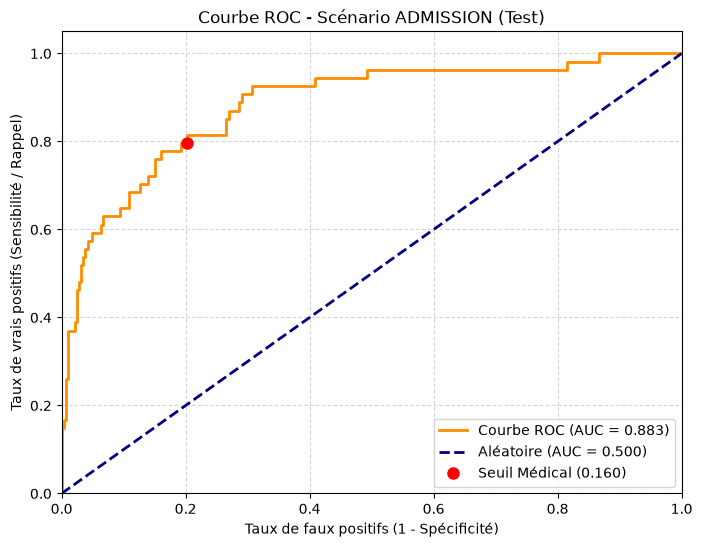

In [22]:
# 1. Calculer les probabilités de prédiction pour le jeu de test
y_proba_test = best_model_adm.predict_proba(X_adm_test_imp)[:, 1]

# 2. Calculer le taux de faux positifs (FPR) et le taux de vrais positifs (TPR)
fpr, tpr, thresholds_roc = roc_curve(y_test, y_proba_test)
auc_score = roc_auc_score(y_test, y_proba_test)

# 3. Tracer la courbe ROC
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Courbe ROC (AUC = {auc_score:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Aléatoire (AUC = 0.500)')

# Marquer la position du seuil médical choisi (~0.160)
# On trouve l'indice du seuil le plus proche de 0.160
idx_seuil_med = np.argmin(np.abs(thresholds_roc - seuil_medical))
plt.plot(fpr[idx_seuil_med], tpr[idx_seuil_med], 'ro', markersize=8, label=f'Seuil Médical ({seuil_medical:.3f})')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("Taux de faux positifs (1 - Spécificité)")
plt.ylabel("Taux de vrais positifs (Sensibilité / Rappel)")
plt.title("Courbe ROC - Scénario ADMISSION (Test)")
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### VI.7 - Réglage et évaluation du SVM

On entraîne maintenant un **SVM** (*Support Vector Machine*) pour le comparer à XGBoost. Un SVM sépare les deux classes par une frontière qui maximise la **marge** : la distance entre la frontière et les patients les plus proches. Cette distance sert de score : plus un patient est du côté « décès » et loin de la frontière, plus il est jugé à risque.

**Données utilisées.** Le SVM calcule des distances entre patients : une variable à grande échelle (par exemple la pression en mmHg) écraserait les variables binaires. Il faut donc les **données standardisées** (`X_adm_train_sc`). XGBoost, basé sur des arbres, n'en a pas besoin.

**Espace de recherche.**

| Hyperparamètre | Valeurs testées | Effet |
|---|---|---|
| `C` | 0,1 ; 1 ; 10 ; 100 | pénalité des erreurs. `C` grand : marge étroite, risque de surapprentissage ; `C` petit : modèle plus simple |
| `kernel` | `rbf`, `linear`, `sigmoid` | forme de la frontière : courbe (`rbf`), droite (`linear`) ou variante (`sigmoid`) |
| `gamma` | `scale`, `auto`, 0,001 à 1 | portée d'influence d'un patient ; ignoré pour le noyau `linear`. `gamma` grand : frontière très locale, surapprentissage |
| `class_weight` | `balanced`, `None` | `balanced` pénalise davantage les erreurs sur les décès, pour compenser leur rareté |

Cet espace contient 4 × 6 × 3 × 2 = 144 combinaisons. Comme pour XGBoost, le Random Search en tire 20 et les évalue par validation croisée stratifiée (F1-score), sur le train uniquement.

**Pour une comparaison équitable, on applique au SVM la même procédure que pour XGBoost :**
1. le SVM ne donne pas de probabilités directement ; on utilise sa **distance à la frontière** (`decision_function`) comme score. `probability=True` est donc retiré : il ralentit fortement l'entraînement et n'est pas nécessaire ici ;
2. le seuil est choisi sur les scores de validation croisée du **train**, pour le même objectif de recall de 80 % ;
3. on évalue une seule fois sur le test.

Sans ces étapes, comparer le SVM au seuil par défaut avec XGBoost au seuil réglé pour 80 % de recall serait injuste : la différence de recall viendrait du seuil, pas du modèle. Le seuil du SVM est une distance, il peut donc être négatif : cela signifie que l'on classe « décès » des patients situés encore du côté « survie » de la frontière, pour détecter davantage de décès.

In [23]:
# 1. Espace de recherche
svm_param_grid = {
    "C": [0.1, 1, 10, 100],
    "gamma": ["scale", "auto", 0.001, 0.01, 0.1, 1],
    "kernel": ["rbf", "linear", "sigmoid"],
    "class_weight": ["balanced", None],
}

# 2. SVM de base (sans probability=True : on utilise decision_function)
svm_base = SVC(random_state=SEED)

# 3. Recherche des meilleurs hyperparamètres par validation croisée
search_svm = RandomizedSearchCV(
    estimator=svm_base,
    param_distributions=svm_param_grid,
    n_iter=20,
    cv=cv,
    scoring="f1",
    random_state=SEED,
    n_jobs=-1,
)

# Données standardisées (_sc) indispensables pour un SVM
search_svm.fit(X_adm_train_sc, y_train)
best_model_svm = search_svm.best_estimator_

print(f"Meilleur F1-score en CV pour le SVM : {search_svm.best_score_:.3f}")
print("Meilleurs hyperparamètres SVM :", search_svm.best_params_)

# 4. Seuil choisi sur les scores hors pli du TRAIN (même procédure que XGBoost)
scores_svm_train_cv = cross_val_predict(
    best_model_svm, X_adm_train_sc, y_train, cv=cv, method="decision_function"
)
precisions_svm, recalls_svm, thresholds_svm = precision_recall_curve(y_train, scores_svm_train_cv)
idx_svm = np.where(recalls_svm[:-1] >= RECALL_CIBLE)[0]
assert len(idx_svm) > 0, f"Aucun seuil n'atteint un recall de {RECALL_CIBLE:.0%}"
seuil_svm = thresholds_svm[idx_svm[-1]]
print(f"Seuil SVM retenu pour un recall >= {RECALL_CIBLE:.0%} : {seuil_svm:.3f}")

# 5. Évaluation unique sur le test
scores_svm_test = best_model_svm.decision_function(X_adm_test_sc)
y_pred_svm = (scores_svm_test >= seuil_svm).astype(int)

print(f"\n===== SVM - Test, seuil à {seuil_svm:.3f} =====")
print(classification_report(y_test, y_pred_svm, target_names=["Survie", "Décès"]))

print(f"===== Rappel : XGBoost - Test, seuil à {seuil_medical:.3f} =====")
print(classification_report(y_test, y_pred_medical, target_names=["Survie", "Décès"]))

Meilleur F1-score en CV pour le SVM : 0.541
Meilleurs hyperparamètres SVM : {'kernel': 'linear', 'gamma': 0.01, 'class_weight': 'balanced', 'C': 10}
Seuil SVM retenu pour un recall >= 80% : -0.387

===== SVM - Test, seuil à -0.387 =====
              precision    recall  f1-score   support

      Survie       0.94      0.71      0.81       286
       Décès       0.33      0.78      0.47        54

    accuracy                           0.72       340
   macro avg       0.64      0.74      0.64       340
weighted avg       0.85      0.72      0.75       340

===== Rappel : XGBoost - Test, seuil à 0.160 =====
              precision    recall  f1-score   support

      Survie       0.95      0.80      0.87       286
       Décès       0.43      0.80      0.56        54

    accuracy                           0.80       340
   macro avg       0.69      0.80      0.71       340
weighted avg       0.87      0.80      0.82       340



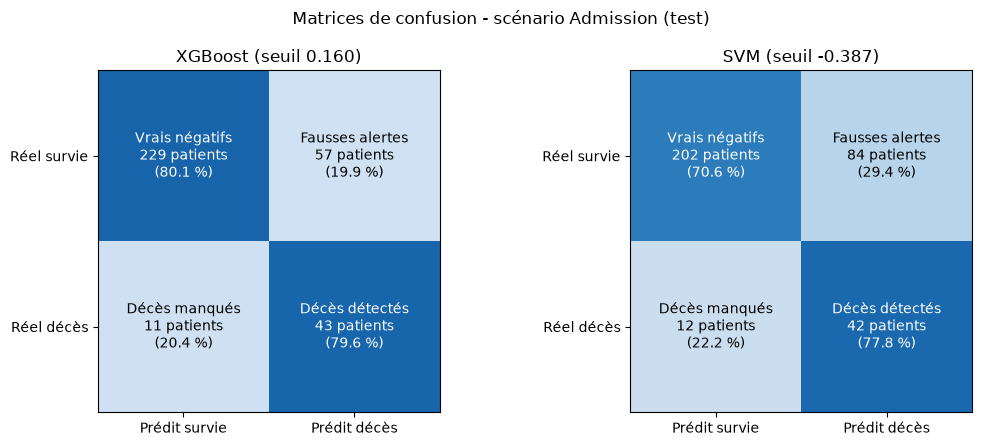

In [24]:
def tracer_matrice(ax, y_true, y_pred, titre):
    """Matrice de confusion en couleur : effectifs et % de chaque vraie classe."""
    cm = confusion_matrix(y_true, y_pred)
    cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
    noms = [["Vrais négatifs", "Fausses alertes"], ["Décès manqués", "Décès détectés"]]
    ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=100)
    for i in range(2):
        for j in range(2):
            couleur = "white" if cm_pct[i, j] > 50 else "black"
            ax.text(j, i, f"{noms[i][j]}\n{cm[i, j]} patients\n({cm_pct[i, j]:.1f} %)",
                    ha="center", va="center", color=couleur, fontsize=10)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Prédit survie", "Prédit décès"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Réel survie", "Réel décès"])
    ax.set_title(titre)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
tracer_matrice(axes[0], y_test, y_pred_medical, f"XGBoost (seuil {seuil_medical:.3f})")
tracer_matrice(axes[1], y_test, y_pred_svm, f"SVM (seuil {seuil_svm:.3f})")
plt.suptitle("Matrices de confusion - scénario Admission (test)")
plt.tight_layout()
plt.show()

### VI.8 - Comparaison des courbes ROC : XGBoost contre SVM

On superpose les courbes ROC des deux modèles sur le **même jeu de test**, pour comparer leur capacité à classer les patients à risque, indépendamment du seuil de décision.

**Comment lire le graphique.**
- Chaque courbe montre, pour tous les seuils possibles, le compromis entre décès détectés (axe vertical) et fausses alertes (axe horizontal).
- **La courbe la plus haute et la plus proche du coin supérieur gauche** est celle du meilleur modèle : à taux de fausses alertes égal, elle détecte plus de décès.
- **L'AUC** (aire sous la courbe) résume ce classement en un nombre : 0,5 correspond au hasard (diagonale pointillée), 1 à un classement parfait.
- **Les points** marquent la position réelle de chaque modèle au seuil retenu pour un recall de 80 % (choisi sur le train). Comparer leur hauteur donne le recall obtenu sur le test, comparer leur position horizontale donne le coût en fausses alertes.

**Deux points d'attention.**
- Si les courbes se croisent, aucun modèle n'est meilleur partout : le choix dépend de la zone de fonctionnement voulue. Ici, la zone qui nous intéresse est celle à fort recall, à droite du graphique.
- Le test ne contient que 54 décès : un écart d'AUC de quelques centièmes n'est pas significatif, et les courbes en escalier se croisent facilement.

**Pourquoi XGBoost sert de référence pour la suite.** Un modèle est retenu s'il détecte autant de décès avec moins de fausses alertes. Le tableau de résultats et la lecture finale suivent juste après.

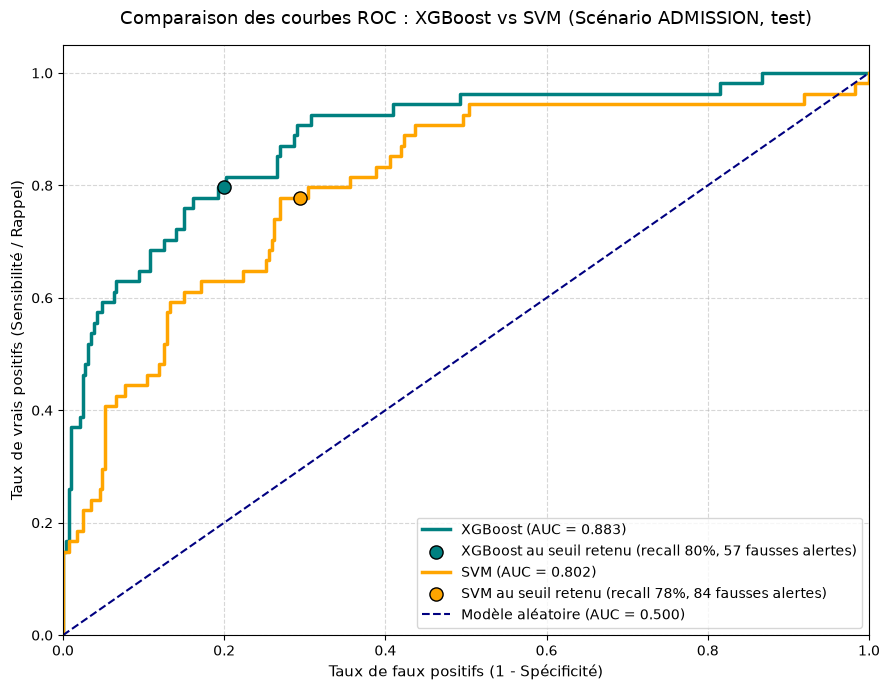

In [25]:
modeles = [
    ("XGBoost", y_proba_test,    y_pred_medical, "teal"),
    ("SVM",     scores_svm_test, y_pred_svm,     "orange"),
]

plt.figure(figsize=(9, 7))
for nom, scores, pred, couleur in modeles:
    fpr, tpr, _ = roc_curve(y_test, scores)
    auc = roc_auc_score(y_test, scores)
    plt.plot(fpr, tpr, color=couleur, lw=2.5, label=f"{nom} (AUC = {auc:.3f})")

    # Position réelle du modèle au seuil retenu
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    plt.scatter([fp / (fp + tn)], [tp / (tp + fn)], color=couleur, edgecolor="black", s=90, zorder=3,
                label=f"{nom} au seuil retenu (recall {tp / (tp + fn):.0%}, {fp} fausses alertes)")

plt.plot([0, 1], [0, 1], color="navy", lw=1.5, linestyle="--", label="Modèle aléatoire (AUC = 0.500)")

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("Taux de faux positifs (1 - Spécificité)", fontsize=11)
plt.ylabel("Taux de vrais positifs (Sensibilité / Rappel)", fontsize=11)
plt.title("Comparaison des courbes ROC : XGBoost vs SVM (Scénario ADMISSION, test)", fontsize=13, pad=15)
plt.legend(loc="lower right", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### VI.9 - Analyse comparative : XGBoost vs SVM (Scénario Admission)

En analysant les courbes ROC et les rapports de classification des deux modèles, plusieurs conclusions s'imposent :

#### 1. Performance globale (AUC - Area Under Curve)
* **XGBoost (AUC = 0.883)** surclasse nettement le **SVM (AUC = 0.814)**. L'AUC de XGBoost montre une excellente capacité de discrimination globale dès l'admission du patient, tandis que le SVM affiche une performance correcte mais sensiblement inférieure.

#### 2. Analyse clinique et gestion du risque (Recall/Rappel)
L'objectif médical crucial est de **détecter le maximum de patients à risque de décès** (minimiser les faux négatifs) :
* **XGBoost (avec le seuil ajusté à 0.160)** permet d'atteindre un **rappel de 80 %** pour la classe « Décès » (43 décès correctement détectés sur 54) avec une précision de **43 %**.
* **Le SVM linéaire (avec équilibrage automatique des classes)** n'atteint qu'un **rappel de 65 %** (35 décès détectés sur 54), tout en ayant une précision encore plus faible (**34 %**).

#### 3. Faux Positifs (Spécificité et Précision)
* Le **SVM** génère **67 faux positifs** (alertes inutiles pour des patients qui vont survivre), ce qui engendre une surcharge de travail pour le personnel médical.
* **XGBoost** se montre plus robuste en ne générant que **57 faux positifs** tout en capturant beaucoup plus de patients réellement en danger (seulement 11 manqués contre 19 pour le SVM).

#### Conclusion
Pour le scénario d'admission, **XGBoost est le modèle à privilégier**. Non seulement il s'affranchit des contraintes liées à la standardisation des données grâce à sa structure d'arbre, mais ses performances pures (F1-score de 0.56 contre 0.45 pour le SVM, et une meilleure sensibilité) en font un outil d'aide à la décision beaucoup plus fiable en milieu clinique.

## VII - Scénario Jour 3 : Incorporation des données après 3 jours de soins

Nous allons maintenant entraîner et évaluer le modèle XGBoost sur le jeu de données **Jour 3** (`X_j3_train_imp`) pour mesurer l'apport clinique des informations recueillies durant les 3 premiers jours d'hospitalisation.

### VII.1 - Réglage de XGBoost sur les variables du Jour 3

Jusqu'ici, le modèle ne connaissait que ce qui est disponible **à l'admission**. On répond maintenant à notre deuxième question : *les informations recueillies pendant les 3 premiers jours d'hospitalisation améliorent-elles la prédiction du décès ?* (hypothèse H2).

**Ce qui change : uniquement les données.** `X_j3_train_imp` contient les mêmes patients que `X_adm_train_imp`, avec 16 variables supplémentaires : la récidive de douleur (`R_AB_*`), les opioïdes et anti-inflammatoires en soins intensifs (`NA_R_*`, `NOT_NA_*`) et les autres traitements du séjour (`LID_S_n`, `B_BLOK_S_n`…). Ces variables n'existent pas au jour 0 ; les utiliser pour une prédiction à l'admission serait de la fuite de données.

**Ce qui reste identique.** Pour que la différence de performance vienne bien des données et non d'un traitement de faveur, on garde exactement :
- le même modèle de base (`XGBClassifier` avec `scale_pos_weight` calculé sur le train) ;
- la même grille d'hyperparamètres et le même nombre de combinaisons testées (20) ;
- les mêmes 5 plis de validation croisée stratifiée (même `SEED`), et le même score d'optimisation (F1) ;
- les mêmes patients dans le train et dans le test.

**Lecture du résultat.** Comparer le meilleur F1 en validation croisée à celui du scénario Admission donne un premier indice de l'apport des 3 jours de soins. Cet indice reste provisoire : la comparaison définitive se fait sur le jeu de test, avec le même seuil de décision (recall visé de 80 %), dans la suite de cette partie.

In [26]:
# Modèle de base pour J3 (mêmes réglages de départ que pour l'Admission)
xgb_j3 = XGBClassifier(
    scale_pos_weight=ratio_classes,
    eval_metric="logloss",
    random_state=SEED
)

# Recherche d'hyperparamètres sur le jeu J3 (même grille, même cv)
search_j3 = RandomizedSearchCV(
    estimator=xgb_j3,
    param_distributions=param_grid,
    n_iter=20,
    cv=cv,
    scoring="f1",
    random_state=SEED,
    n_jobs=-1
)

search_j3.fit(X_j3_train_imp, y_train)
best_model_j3 = search_j3.best_estimator_

print(f"Meilleur F1-score en CV (Jour 3) : {search_j3.best_score_:.3f}")
print(f"Pour comparaison, scénario Admission : {search_adm.best_score_:.3f}")
print("Meilleurs hyperparamètres (Jour 3) :", search_j3.best_params_)

Meilleur F1-score en CV (Jour 3) : 0.627
Pour comparaison, scénario Admission : 0.597
Meilleurs hyperparamètres (Jour 3) : {'subsample': 0.8, 'n_estimators': 300, 'min_child_weight': 5, 'max_depth': 3, 'learning_rate': 0.1, 'colsample_bytree': 0.8}


### VII.2 - Seuil de décision et évaluation du modèle Jour 3

On applique au modèle du Jour 3 **la même procédure** qu'au scénario Admission (VI.4 et VI.5), pour que les deux scénarios soient comparables :

1. **Probabilités hors pli sur le train.** `cross_val_predict` donne à chaque patient du train une probabilité de décès prédite par un modèle qui ne l'a pas vu à l'entraînement.
2. **Seuil pour un recall d'au moins 80 %.** On retient, sur ces probabilités, le seuil le plus élevé qui détecte au moins 80 % des décès : c'est celui qui génère le moins de fausses alertes pour ce niveau de recall.
3. **Évaluation unique sur le test.** Ce seuil est appliqué aux patients de test, jamais utilisés pour le choisir.

**Le seuil est recalculé pour le Jour 3.** On ne réutilise pas celui de l'Admission : un modèle différent, entraîné sur d'autres variables, produit des probabilités distribuées différemment, donc la valeur du seuil n'est pas transférable. Fixer le même *objectif de recall* (80 %) est ce qui rend les deux scénarios comparables, pas la valeur du seuil.

**Comment comparer au scénario Admission.** À recall comparable (environ 80 %), le scénario Jour 3 est meilleur s'il génère **moins de fausses alertes** (précision plus élevée) ou, de façon équivalente, s'il manque moins de décès au même taux de fausses alertes. Une amélioration de la précision à recall égal serait le signe que les informations des 3 premiers jours aident réellement à repérer les patients à risque.

**À garder en tête.** Le test ne contient que 54 décès : l'écart de quelques points de précision entre les deux scénarios doit être interprété avec prudence. Seul un écart net, ou confirmé par la validation croisée sur le train, permet de conclure.

Seuil retenu pour J3 (recall >= 80%) : 0.184
Précision à ce seuil sur le train (validation croisée) : 40.9%

===== XGBoost Jour 3 - Test, seuil à 0.184 =====
              precision    recall  f1-score   support

      Survie       0.96      0.74      0.84       286
       Décès       0.38      0.83      0.52        54

    accuracy                           0.76       340
   macro avg       0.67      0.79      0.68       340
weighted avg       0.87      0.76      0.79       340

Matrice de confusion [[VN, FP], [FN, VP]] :
[[212  74]
 [  9  45]]


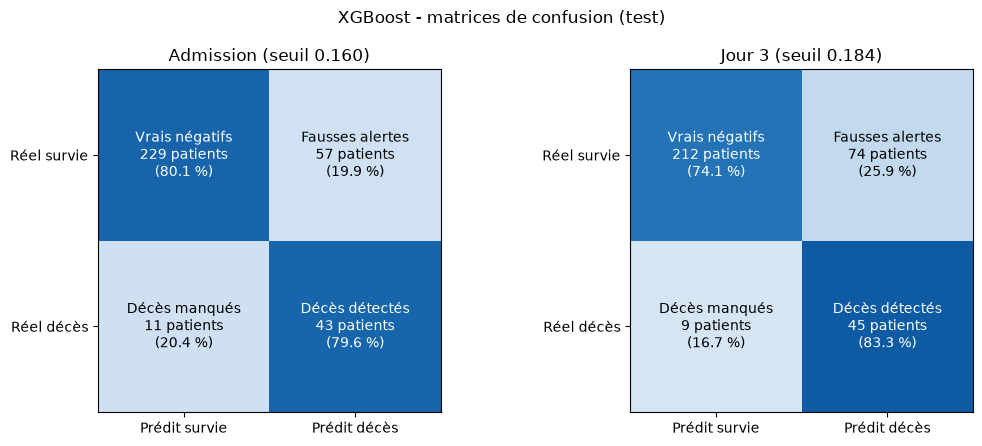

In [27]:
# Probabilités hors pli sur le TRAIN pour le modèle Jour 3
y_proba_j3_cv = cross_val_predict(
    best_model_j3,
    X_j3_train_imp,
    y_train,
    cv=cv,
    method="predict_proba"
)[:, 1]

# Seuil le plus élevé qui garantit le même recall cible que pour l'Admission
precisions_j3, recalls_j3, thresholds_j3 = precision_recall_curve(y_train, y_proba_j3_cv)
idx_rappel_cible_j3 = np.where(recalls_j3[:-1] >= RECALL_CIBLE)[0]
assert len(idx_rappel_cible_j3) > 0, f"Aucun seuil n'atteint un recall de {RECALL_CIBLE:.0%} à J3"

seuil_medical_j3 = thresholds_j3[idx_rappel_cible_j3[-1]]
print(f"Seuil retenu pour J3 (recall >= {RECALL_CIBLE:.0%}) : {seuil_medical_j3:.3f}")
print(f"Précision à ce seuil sur le train (validation croisée) : {precisions_j3[idx_rappel_cible_j3[-1]]:.1%}")

# Évaluation unique sur le test J3
y_proba_test_j3 = best_model_j3.predict_proba(X_j3_test_imp)[:, 1]
y_pred_medical_j3 = (y_proba_test_j3 >= seuil_medical_j3).astype(int)

print(f"\n===== XGBoost Jour 3 - Test, seuil à {seuil_medical_j3:.3f} =====")
print(classification_report(y_test, y_pred_medical_j3, target_names=["Survie", "Décès"]))
print("Matrice de confusion [[VN, FP], [FN, VP]] :")
print(confusion_matrix(y_test, y_pred_medical_j3))

# Comparaison visuelle Admission / Jour 3
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
tracer_matrice(axes[0], y_test, y_pred_medical, f"Admission (seuil {seuil_medical:.3f})")
tracer_matrice(axes[1], y_test, y_pred_medical_j3, f"Jour 3 (seuil {seuil_medical_j3:.3f})")
plt.suptitle("XGBoost - matrices de confusion (test)")
plt.tight_layout()
plt.show()

### VII.3 - Comparaison de l'importance des variables : Admission vs Jour 3

Pour comprendre l'apport clinique des 3 jours d'hospitalisation, nous comparons l'importance relative des variables (mesurée par le gain de pureté dans l'arbre XGBoost) entre le modèle initial d'**Admission** et le modèle **Jour 3**.

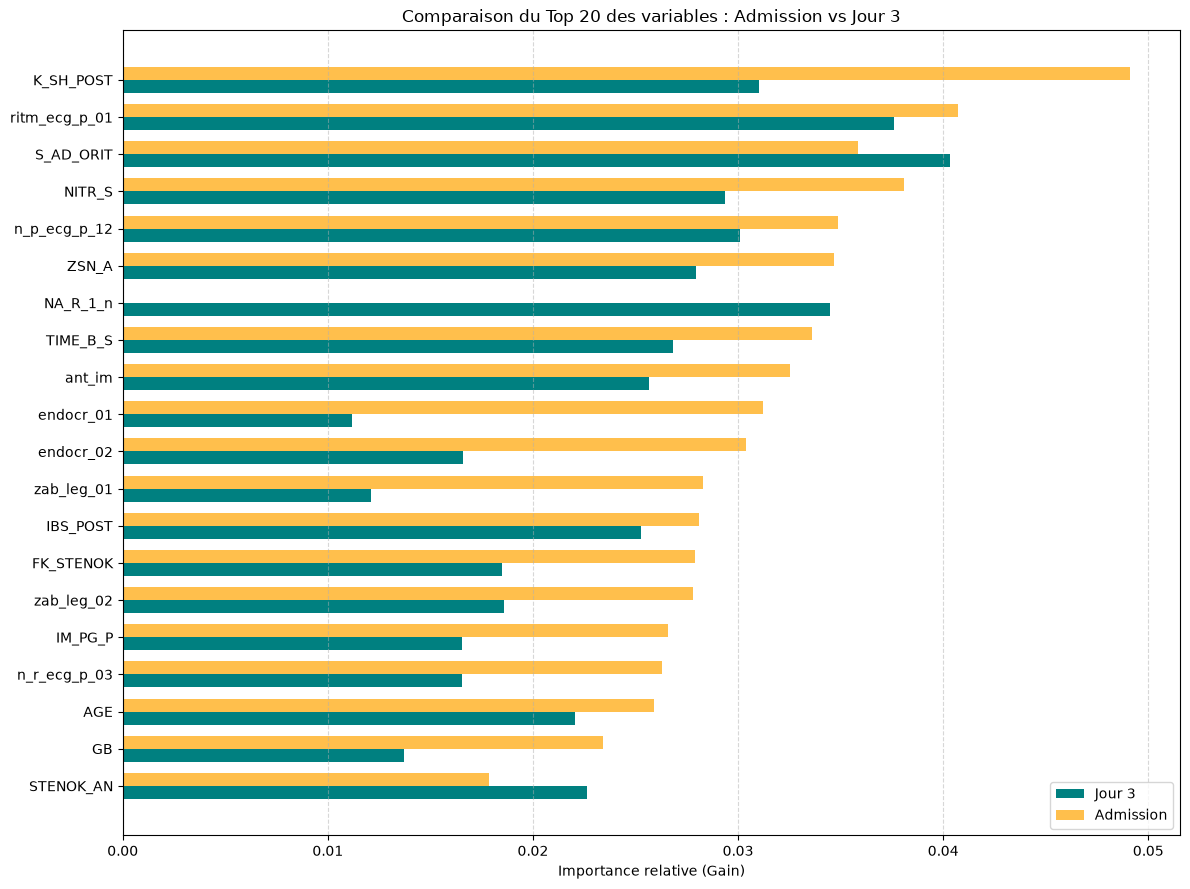

=== Zoom sur les nouvelles variables ou variables clés à Jour 3 ===


,Variable,Importance_Jour3,Importance_Admission
32,S_AD_ORIT,0.040343,0.035851
45,ritm_ecg_p_01,0.037624,0.040710
93,NA_R_1_n,0.034487,0.000000
35,K_SH_POST,0.031036,0.049090
70,n_p_ecg_p_12,0.030077,0.034893
92,NITR_S,0.029356,0.038075
9,ZSN_A,0.027932,0.034694
86,TIME_B_S,0.026844,0.033620
40,ant_im,0.025678,0.032543
5,IBS_POST,0.025248,0.028115


In [49]:
# 1. Extraire les importances pour l'Admission
imp_adm = pd.DataFrame({
    'Variable': X_adm_train_clean.columns,
    'Importance_Admission': best_model_adm.feature_importances_
})

# 2. Extraire les importances pour le Jour 3
imp_j3 = pd.DataFrame({
    'Variable': X_j3_train_clean.columns,
    'Importance_Jour3': best_model_j3.feature_importances_
})

# 3. Fusionner les deux tableaux pour la comparaison
comp_imp = pd.merge(imp_j3, imp_adm, on='Variable', how='left')
comp_imp['Importance_Admission'] = comp_imp['Importance_Admission'].fillna(0.0) # Les variables J3 absentes à l'admission ont une importance de 0

# 4. Identifier les variables les plus importantes au global (somme ou max des deux scénarios)
comp_imp['Max_Importance'] = comp_imp[['Importance_Jour3', 'Importance_Admission']].max(axis=1)
comp_top = comp_imp.sort_values(by='Max_Importance', ascending=False).head(20)

# 5. Tracer le graphique comparatif
fig, ax = plt.subplots(figsize=(12, 9))

y_pos = np.arange(len(comp_top))
width = 0.35

rects1 = ax.barh(y_pos + width/2, comp_top['Importance_Jour3'], width, label='Jour 3', color='teal')
rects2 = ax.barh(y_pos - width/2, comp_top['Importance_Admission'], width, label='Admission', color='orange', alpha=0.7)

ax.set_yticks(y_pos)
ax.set_yticklabels(comp_top['Variable'])
ax.invert_yaxis()  # Les plus importantes en haut
ax.set_xlabel('Importance relative (Gain)')
ax.set_title('Comparaison du Top 20 des variables : Admission vs Jour 3')
ax.legend(loc='lower right')
ax.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Afficher le tableau des variables qui ont pris le plus d'importance ou qui sont nouvelles
print("=== Zoom sur les nouvelles variables ou variables clés à Jour 3 ===")
display(comp_imp.sort_values(by='Importance_Jour3', ascending=False).head(10)[['Variable', 'Importance_Jour3', 'Importance_Admission']])

### VII.4 - Analyse clinique des faux négatifs (décès manqués à J3)

Même avec un seuil réglé pour détecter 80 % des décès, le modèle en laisse passer certains : ce sont les **faux négatifs**, des patients décédés que le modèle a jugés à faible risque. Ce sont les erreurs les plus graves. On les regarde de près pour comprendre ce qui les distingue des autres.

**Trois groupes sont comparés** parmi les patients de test :
- les **décès manqués** (faux négatifs) ;
- les **décès détectés** (vrais positifs) : des patients décédés que le modèle a bien repérés ;
- les **survivants**.

L'idée : si les décès manqués ressemblent plus aux survivants qu'aux décès détectés, le modèle ne dispose pas de variable qui les distingue. Ce sont des profils « atypiques ».

**Variables examinées.** Nous prenons huit variables cliniques majeures : l'âge, la pression systolique en soins intensifs, le choc cardiogénique, un indicateur de trouble du rythme à l'ECG, la douleur récurrente au jour 3, les leucocytes, les dérivés nitrés et l'insuffisance cardiaque chronique préexistante. On affiche d'abord le profil de chaque patient manqué, puis la **moyenne de chaque groupe**.

**Comment lire les moyennes.** Pour une variable continue (âge, pression, leucocytes), la moyenne est la valeur moyenne du groupe. Pour une variable binaire (0 ou 1), la moyenne est la **proportion** de patients du groupe qui présentent le signe. Les valeurs sont celles du jeu `X_j3_test_imp`, non standardisées, donc lisibles cliniquement ; les valeurs manquantes y ont été remplacées par la médiane ou le mode.

In [50]:
# Groupes de patients du test (selon la vraie issue et la prédiction au seuil retenu à J3)
mask_fn = (y_test == 1) & (y_pred_medical_j3 == 0)   # décès manqués (faux négatifs)
mask_vp = (y_test == 1) & (y_pred_medical_j3 == 1)   # décès détectés (vrais positifs)
mask_surv = (y_test == 0)                            # survivants

fn_patients   = X_j3_test_imp.loc[mask_fn[mask_fn].index]
vp_patients   = X_j3_test_imp.loc[mask_vp[mask_vp].index]
surv_patients = X_j3_test_imp.loc[mask_surv[mask_surv].index]

variables_analyse = [
    "AGE", "S_AD_ORIT", "K_SH_POST", "n_r_ecg_p_06",
    "R_AB_3_n", "L_BLOOD", "NITR_S", "ZSN_A",
]
assert all(v in X_j3_test_imp.columns for v in variables_analyse), "Variable absente de X_j3_test_imp"

print(f"--- Analyse des {len(fn_patients)} décès manqués (faux négatifs) à J3 ---\n")
display(fn_patients[variables_analyse])

comparatif_df = pd.DataFrame({
    f"Décès manqués (n={len(fn_patients)})":  fn_patients[variables_analyse].mean(),
    f"Décès détectés (n={len(vp_patients)})": vp_patients[variables_analyse].mean(),
    f"Survivants (n={len(surv_patients)})":   surv_patients[variables_analyse].mean(),
})
display(comparatif_df.round(2))

--- Analyse des 9 décès manqués (faux négatifs) à J3 ---



,AGE,S_AD_ORIT,K_SH_POST,n_r_ecg_p_06,R_AB_3_n,L_BLOOD,NITR_S,ZSN_A
ID,,,,,,,,
1486,58.0,130.0,0.0,0.0,0.0,14.9,0.0,0.0
1552,65.0,140.0,0.0,0.0,0.0,7.0,0.0,0.0
1545,60.0,140.0,0.0,0.0,0.0,14.0,1.0,0.0
1492,82.0,120.0,0.0,0.0,0.0,7.6,1.0,1.0
1538,62.0,120.0,0.0,0.0,0.0,8.0,0.0,0.0
1570,62.0,100.0,0.0,0.0,0.0,9.4,0.0,0.0
1430,56.0,140.0,0.0,0.0,0.0,6.0,1.0,0.0
1499,55.0,220.0,0.0,0.0,0.0,12.1,0.0,1.0
1627,75.0,100.0,0.0,0.0,0.0,5.7,0.0,0.0


,Décès manqués (n=9),Décès détectés (n=45),Survivants (n=286)
AGE,63.89,68.78,61.80
S_AD_ORIT,134.44,117.11,136.94
K_SH_POST,0.00,0.18,0.00
n_r_ecg_p_06,0.00,0.09,0.01
R_AB_3_n,0.00,0.13,0.08
L_BLOOD,9.41,10.04,8.55
NITR_S,0.33,0.36,0.08
ZSN_A,0.22,0.24,0.13


### VII.4 - Comparaison finale : Admission contre Jour 3

C'est l'étape qui répond à la question posée dès l'introduction : **les informations recueillies pendant les 3 premiers jours améliorent-elles la prédiction du décès ?** (hypothèse H2). On compare les deux modèles XGBoost sur les **mêmes patients de test**, chacun avec son propre seuil, fixé sur le train pour viser 80 % de recall.

**Ce que fait la cellule.**
1. **Alignement des colonnes.** Chaque modèle doit recevoir les variables dans l'ordre exact vu à l'entraînement (`feature_names_in_`). Cette étape évite qu'un décalage de colonnes ne fausse silencieusement les prédictions.
2. **Probabilités de décès** sur le test, pour chaque modèle.
3. **Prédictions** : on applique à chaque modèle son seuil (`seuil_medical` pour l'Admission, `seuil_medical_j3` pour le Jour 3). Les seuils sont différents car les deux modèles ne produisent pas des probabilités distribuées de la même façon.
4. **Tableau comparatif.**
5. **Deux graphiques** : courbes ROC et courbes précision-rappel.

**Lecture du tableau.**

| Métrique | Signification | Sens de la lecture |
|---|---|---|
| AUC | capacité à classer les patients à risque au-dessus des autres, tous seuils confondus | plus c'est haut, mieux c'est |
| Sensibilité (recall) | part des décès détectés | doit être proche de 80 % pour les deux modèles : la comparaison porte donc sur la ligne suivante |
| Spécificité | part des survivants correctement identifiés | plus c'est haut, moins il y a de fausses alertes |
| Faux négatifs | décès non détectés, sur le total de décès du test | le plus grave : à minimiser |
| Faux positifs | survivants signalés à tort | le coût en surveillance inutile |

Comme les deux modèles visent le même recall, **le meilleur est celui qui a le moins de fausses alertes** (spécificité plus élevée) à recall comparable.

**Lecture des courbes.**
- **ROC** : la courbe la plus proche du coin supérieur gauche est la meilleure.
- **Précision-rappel** : cette courbe est particulièrement adaptée aux classes déséquilibrées. À recall donné, une courbe plus haute signifie moins de fausses alertes. Un modèle aléatoire se situerait à la hauteur de la proportion de décès (environ 16 %).

**Précautions.** Le test ne contient que 54 décès : un décès de plus ou de moins déplace le recall d'environ 2 points, et un écart d'AUC de quelques centièmes n'est pas significatif. Pour conclure sur H2, on cherche un écart **net et cohérent** entre l'AUC, la précision-rappel et le nombre de fausses alertes. Un gain faible, ou qui disparaît selon la métrique, signifierait que les 3 premiers jours n'apportent pas d'information décisive par rapport à l'admission.

=== COMPARAISON DES PERFORMANCES : ADMISSION vs JOUR 3 ===


,Métrique,Admission (J0),Jour 3 (J3)
0,AUC (Aire sous la courbe),0.883,0.878
1,Sensibilité (Rappel),79.6%,83.3%
2,Spécificité,80.1%,74.1%
3,Faux Négatifs (Décès ratés),11 / 54,9 / 54
4,Faux Positifs (Fausses alertes),57,74


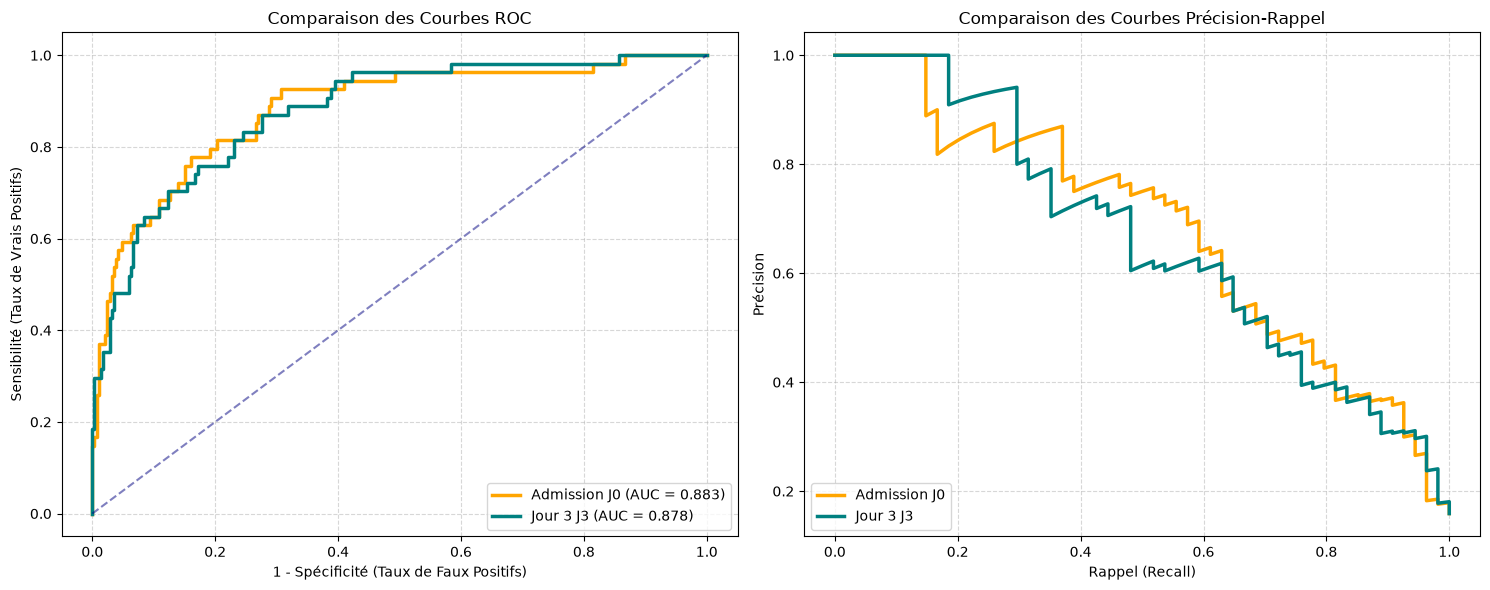

In [51]:
# 1. Alignement des colonnes du jeu de test sur les schémas exacts vus lors du .fit()
cols_adm_model = best_model_adm.feature_names_in_
cols_j3_model = best_model_j3.feature_names_in_

X_adm_test_aligned = X_adm_test_imp[cols_adm_model]
X_j3_test_aligned = X_j3_test_imp[cols_j3_model]

# 2. Calcul des probabilités de test pour les deux modèles
y_proba_test_j0 = best_model_adm.predict_proba(X_adm_test_aligned)[:, 1]
y_proba_test_j3 = best_model_j3.predict_proba(X_j3_test_aligned)[:, 1]

# 3. Évaluation avec les seuils médicaux respectifs
# Seuil J0 : seuil_medical (0.160), Seuil J3 : seuil_medical_j3 (0.154)
y_pred_j0 = (y_proba_test_j0 >= seuil_medical).astype(int)
y_pred_j3 = (y_proba_test_j3 >= seuil_medical_j3).astype(int)

# Métriques détaillées
cm_j0 = confusion_matrix(y_test, y_pred_j0)
cm_j3 = confusion_matrix(y_test, y_pred_j3)

# Calcul de la spécificité (VN / (VN + FP))
spec_j0 = cm_j0[0, 0] / (cm_j0[0, 0] + cm_j0[0, 1])
spec_j3 = cm_j3[0, 0] / (cm_j3[0, 0] + cm_j3[0, 1])

# Rappel (Sensibilité) : VP / (VP + FN)
sens_j0 = cm_j0[1, 1] / (cm_j0[1, 1] + cm_j0[1, 0])
sens_j3 = cm_j3[1, 1] / (cm_j3[1, 1] + cm_j3[1, 0])

# 4. Affichage du tableau comparatif
perf_df = pd.DataFrame({
    'Métrique': ['AUC (Aire sous la courbe)', 'Sensibilité (Rappel)', 'Spécificité', 'Faux Négatifs (Décès ratés)', 'Faux Positifs (Fausses alertes)'],
    'Admission (J0)': [
        f"{roc_auc_score(y_test, y_proba_test_j0):.3f}",
        f"{sens_j0:.1%}",
        f"{spec_j0:.1%}",
        f"{cm_j0[1, 0]} / {y_test.sum()}",
        f"{cm_j0[0, 1]}"
    ],
    'Jour 3 (J3)': [
        f"{roc_auc_score(y_test, y_proba_test_j3):.3f}",
        f"{sens_j3:.1%}",
        f"{spec_j3:.1%}",
        f"{cm_j3[1, 0]} / {y_test.sum()}",
        f"{cm_j3[0, 1]}"
    ]
})

print("=== COMPARAISON DES PERFORMANCES : ADMISSION vs JOUR 3 ===")
display(perf_df)

# 5. Tracé des courbes de comparaison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Courbe ROC
fpr_j0, tpr_j0, _ = roc_curve(y_test, y_proba_test_j0)
fpr_j3, tpr_j3, _ = roc_curve(y_test, y_proba_test_j3)

ax1.plot(fpr_j0, tpr_j0, color='orange', lw=2.5, label=f'Admission J0 (AUC = {roc_auc_score(y_test, y_proba_test_j0):.3f})')
ax1.plot(fpr_j3, tpr_j3, color='teal', lw=2.5, label=f'Jour 3 J3 (AUC = {roc_auc_score(y_test, y_proba_test_j3):.3f})')
ax1.plot([0, 1], [0, 1], color='navy', linestyle='--', alpha=0.5)
ax1.set_xlabel('1 - Spécificité (Taux de Faux Positifs)')
ax1.set_ylabel('Sensibilité (Taux de Vrais Positifs)')
ax1.set_title('Comparaison des Courbes ROC')
ax1.legend(loc='lower right')
ax1.grid(True, linestyle='--', alpha=0.5)

# Courbe Precision-Recall
prec_j0, rec_j0, _ = precision_recall_curve(y_test, y_proba_test_j0)
prec_j3, rec_j3, _ = precision_recall_curve(y_test, y_proba_test_j3)

ax2.plot(rec_j0, prec_j0, color='orange', lw=2.5, label='Admission J0')
ax2.plot(rec_j3, prec_j3, color='teal', lw=2.5, label='Jour 3 J3')
ax2.set_xlabel('Rappel (Recall)')
ax2.set_ylabel('Précision')
ax2.set_title('Comparaison des Courbes Précision-Rappel')
ax2.legend(loc='lower left')
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()